# SmartForum IR
### An Intelligent, Multi-Stage Information Retrieval System for Technical Discussion Archives

## 1. Problem statement

Online technical communities (Usenet, Stack Exchange, product forums, mailing lists) accumulate millions of short, noisy, informal posts. A user who types *"upgrading RAM in a Macintosh"* or *"clipper chip key escrow"* expects the system to

1. **find** the relevant posts even when the exact words differ (vocabulary mismatch),
2. **rank** them sensibly using many weak signals, not just keyword overlap,
3. **filter out** spam, gibberish and near-duplicate posts,
4. **organise** the archive (topics, clusters, categories) so it can be browsed,
5. **keep up** with a continuous stream of new posts, and
6. let the user **converse** with the archive (follow-up questions) and even search **images** with text.

**SmartForum IR** is a complete retrieval pipeline that does all six, built from scratch and from standard libraries, and evaluated with proper IR metrics.

## 2. Dataset

**20 Newsgroups** (Lang, 1995; bundled loader in `scikit-learn`). We use **8 groups** with deliberately mixed closeness (two computer-hardware/graphics groups that overlap, plus very different groups), **500 posts per group → ~4,000 posts**. Headers, signatures and quoted replies are stripped so the model cannot cheat from metadata.

`comp.graphics` · `comp.sys.mac.hardware` · `rec.autos` · `rec.sport.baseball` · `sci.crypt` · `sci.med` · `sci.space` · `misc.forsale`

## 3. Syllabus coverage map

| # | Syllabus topic | Where / what we do in this notebook |
|---|---|---|
| 1 | Inverted index, TF-IDF, **BM25** | 6 – built from scratch, parameters tuned (k1, b heat-map) |
| 2 | **Word embeddings** | 7 – Word2Vec (or LSA fallback), neighbours, t-SNE of words, embedding retrieval |
| 3 | **Neural IR / semantic search** | 8 – Sentence-BERT + FAISS, hybrid BM25+dense fusion (RRF) |
| 4 | **Neural networks & BERT** | 8, 11 – BERT bi-encoder, cross-encoder re-ranker, MLP classifier on BERT embeddings |
| 5 | **Dimensionality reduction** | 9 – PCA, SVD scree, t-SNE maps (static + interactive) |
| 6 | **Clustering-based retrieval** | 9 – k-means, cluster-pruned search (speed vs accuracy), near-duplicate grouping |
| 7 | **Topic modeling** | 10 – LDA vs NMF, coherence, topic→category heat-map, topic similarity as a ranking signal |
| 8 | **Feature engineering** | 11 – stylistic/structural features, ablation |
| 9 | **Classification-based retrieval** | 11 – query classification → category filtering / boosting |
| 10 | **Ensemble methods** | 11 – soft voting and stacking of heterogeneous models |
| 11 | **Anomaly detection** | 12 – Isolation Forest vs LOF vs One-Class SVM, review queue |
| 12 | **Learning to Rank** | 13 – LambdaMART / GBDT over 14 features, ablations, learning curve |
| 13 | **Multimodal retrieval & CLIP** | 14 – text→image search with CLIP |
| 14 | **Chatbot-based (conversational) search** | 15 – multi-turn assistant with query rewriting + extractive answers |
| 15 | **Real-time / streaming IR** | 16 – incremental index, online clustering, burst detection, latency curves |
| 16 | **Evaluation** | 6.1 + 17 – P@10, nDCG@10, MAP@100, MRR, dashboard |

## 4. System architecture and evaluation protocol

The figure below shows the stages. Evaluation protocol (important for honesty):

* **Relevance judgements** are *proxy / weakly supervised*: a post is **relevant (grade 1)** if it is from the query's newsgroup, and **highly relevant (grade 2)** if it additionally contains the query terms. This is standard practice when no human-labelled test collection exists, but it is **not** a human relevance judgement; absolute numbers should be read as *relative comparisons between methods*.
* **16 hand-written queries** (2 per group) + **200 automatically generated queries** (25 per group, built from test-split documents). Parameters are tuned only on the *training* queries; all reported numbers use *held-out* queries.

In [1]:
# ============================================================
# 0. SETUP
# ============================================================
import os, re, sys, time, math, random, string, warnings, subprocess, heapq, textwrap
from collections import Counter, defaultdict
from operator import itemgetter
warnings.filterwarnings("ignore")

# On Google Colab set this to True once to install the optional neural / ANN libraries
INSTALL_OPTIONAL = False
if INSTALL_OPTIONAL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "sentence-transformers", "faiss-cpu", "gensim", "lightgbm", "plotly"], check=False)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from matplotlib.ticker import MaxNLocator
try:
    from IPython.display import display
except Exception:
    display = print

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA, LatentDirichletAllocation, NMF
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.preprocessing import normalize, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC, OneClassSVM
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import ExtraTreesClassifier, IsolationForest, GradientBoostingRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score, roc_auc_score,
                             roc_curve, average_precision_score, precision_recall_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

def _has(mod):
    try:
        __import__(mod); return True
    except Exception:
        return False

HAS_ST, HAS_FAISS, HAS_GENSIM, HAS_LGB, HAS_PLOTLY = (_has("sentence_transformers"), _has("faiss"),
                                                      _has("gensim"), _has("lightgbm"), _has("plotly"))
print("Optional libraries ->",
      {"sentence-transformers": HAS_ST, "faiss": HAS_FAISS, "gensim": HAS_GENSIM,
       "lightgbm": HAS_LGB, "plotly": HAS_PLOTLY})
print("Missing ones are replaced by lighter fall-backs (LSA embeddings, numpy search, sklearn GBDT, ...).")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
RESULTS = {}      # collected numbers for the final dashboard

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2


Optional libraries -> {'sentence-transformers': False, 'faiss': True, 'gensim': False, 'lightgbm': True, 'plotly': False}
Missing ones are replaced by lighter fall-backs (LSA embeddings, numpy search, sklearn GBDT, ...).


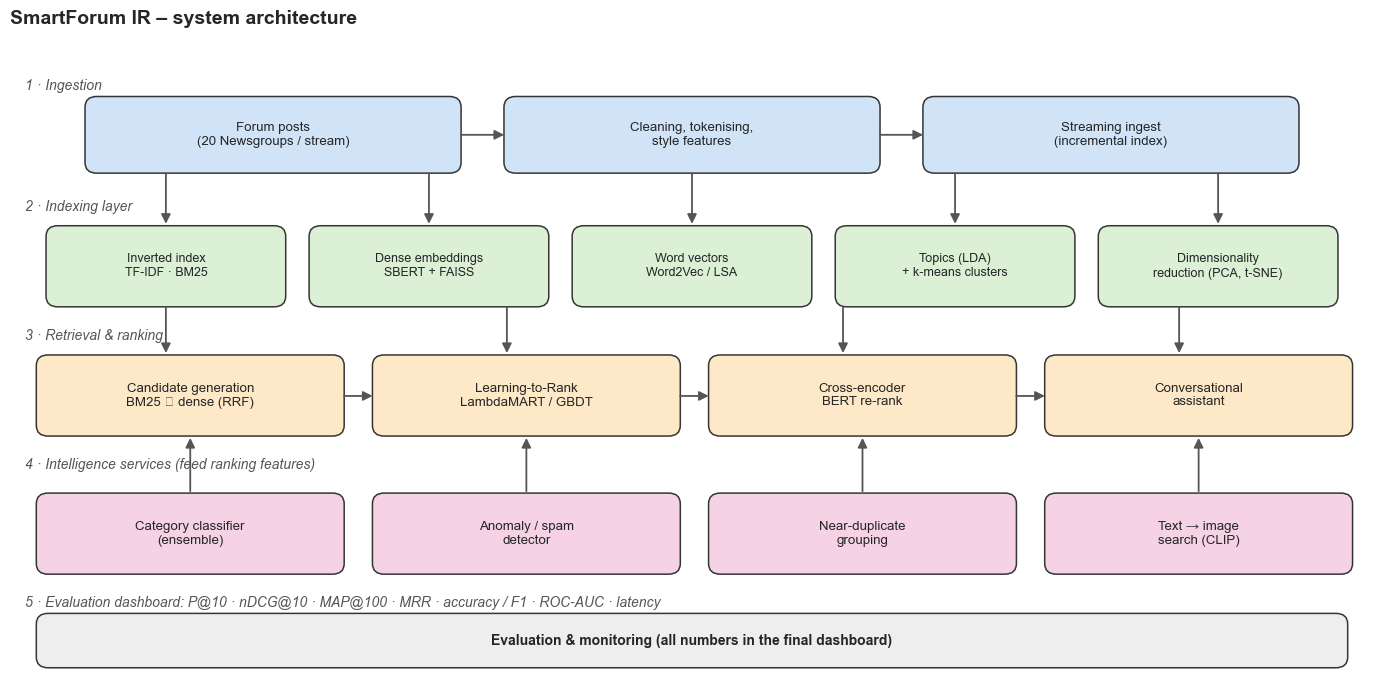

In [2]:
# ============================================================
# 0b. ARCHITECTURE DIAGRAM
# ============================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.2); ax.axis("off")

def box(x, y, w, h, text, color, fs=9.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12",
                                fc=color, ec="#2b2b2b", lw=1.1, alpha=0.95))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color="#555"))

def caption(y, s): ax.text(0.15, y, s, fontsize=10, color="#555", fontstyle="italic")

c1, c2, c3, c4 = "#cfe3f7", "#d9f0d3", "#fde7c4", "#f5d0e3"
caption(6.55, "1 · Ingestion")
for i, t in enumerate(["Forum posts\n(20 Newsgroups / stream)", "Cleaning, tokenising,\nstyle features", "Streaming ingest\n(incremental index)"]):
    box(0.8 + i * 4.3, 5.65, 3.8, 0.8, t, c1)
for i in range(2): arrow(4.6 + i * 4.3, 6.05, 5.1 + i * 4.3, 6.05)

caption(5.2, "2 · Indexing layer")
idx = ["Inverted index\nTF-IDF · BM25", "Dense embeddings\nSBERT + FAISS", "Word vectors\nWord2Vec / LSA", "Topics (LDA)\n+ k-means clusters", "Dimensionality\nreduction (PCA, t-SNE)"]
for i, t in enumerate(idx):
    box(0.4 + i * 2.7, 4.15, 2.4, 0.85, t, c2, fs=9)
for i in range(5): arrow(1.6 + i * 2.7, 5.65, 1.6 + i * 2.7, 5.02)

caption(3.75, "3 · Retrieval & ranking")
rk = ["Candidate generation\nBM25 ⊕ dense (RRF)", "Learning-to-Rank\nLambdaMART / GBDT", "Cross-encoder\nBERT re-rank", "Conversational\nassistant"]
for i, t in enumerate(rk):
    box(0.3 + i * 3.45, 2.7, 3.1, 0.85, t, c3)
for i in range(3): arrow(3.4 + i * 3.45, 3.12, 3.75 + i * 3.45, 3.12)
for x in (1.6, 5.1, 8.55, 12.0): arrow(x, 4.15, x, 3.57)

caption(2.3, "4 · Intelligence services (feed ranking features)")
sv = ["Category classifier\n(ensemble)", "Anomaly / spam\ndetector", "Near-duplicate\ngrouping", "Text → image\nsearch (CLIP)"]
for i, t in enumerate(sv):
    box(0.3 + i * 3.45, 1.15, 3.1, 0.85, t, c4)
for x in (1.85, 5.3, 8.75, 12.2): arrow(x, 2.02, x, 2.68)

caption(0.75, "5 · Evaluation dashboard: P@10 · nDCG@10 · MAP@100 · MRR · accuracy / F1 · ROC-AUC · latency")
box(0.3, 0.1, 13.4, 0.55, "Evaluation & monitoring (all numbers in the final dashboard)", "#eeeeee", fs=10, bold=True)
ax.set_title("SmartForum IR – system architecture", fontsize=14, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

## 5. Data loading, cleaning and exploration

We load the corpus, remove e-mail addresses / URLs / non-ASCII noise, drop posts shorter than 25 words and keep a stratified **500 posts per newsgroup**. We also create an **80/20 stratified split** (`train_idx` / `test_idx`): classifiers are trained on `train_idx`, and all *automatic* test queries are built from `test_idx` documents, so nothing leaks.

!! Could not download 20 Newsgroups -> SSLError
!! Using the SYNTHETIC fall-back corpus. Re-run with internet access for real results.
SYNTHETIC fall-back corpus: 4000 posts, 8 groups, train/test = 3000/1000


,doc_id,short,n_words,snippet
0,0,hardware,105,Upgrade manual about for about which if in. Di...
1,1,med,136,As other for think their but some their have a...
2,2,hardware,132,Have mhz by all if you about has for scsi for ...
3,3,space,137,This from more have make resolution what this....
4,4,crypt,53,The which on is was manager by. Of have work p...


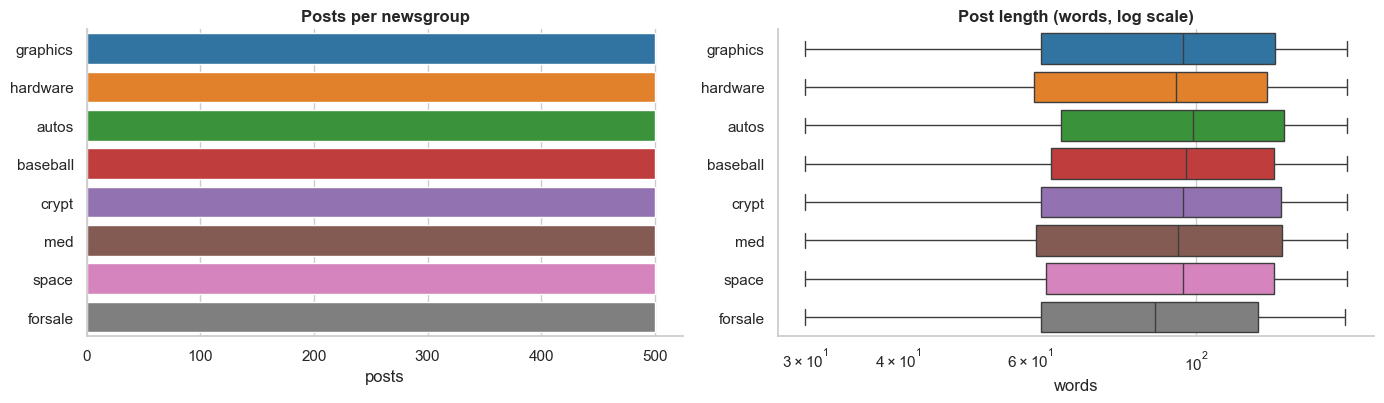

In [3]:
# ============================================================
# 1. DATA
# ============================================================
CATS = ["comp.graphics", "comp.sys.mac.hardware", "rec.autos", "rec.sport.baseball",
        "sci.crypt", "sci.med", "sci.space", "misc.forsale"]
SHORT = {c: c.split(".")[-1] for c in CATS}
CAT_PAL = dict(zip(CATS, sns.color_palette("tab10", 8)))
N_PER_CAT = 500
USING_REAL_DATA = False

def make_synthetic_corpus(n_per_cat=540, seed=SEED):
    """Offline fall-back: topic-conditioned bag-of-words posts (Zipf word choice + shared noise)."""
    rng = np.random.default_rng(seed)
    T = {
     "comp.graphics": "image images graphics pixel pixels color colors rendering render polygon texture vector bitmap jpeg gif resolution animation shader opengl format viewer software display palette ray tracing mesh algorithm visualization conversion convert file files program monitor video card".split(),
     "comp.sys.mac.hardware": "mac macintosh apple powerbook quadra centris performa simm ram drive scsi monitor motherboard cpu modem floppy cache upgrade card slot nubus powerpc mhz keyboard disk memory port adapter video display".split(),
     "rec.autos": "car cars engine tires brake transmission dealer sedan mileage honda toyota ford bmw driving oil clutch turbo horsepower highway wheel suspension insurance convertible gas mpg model vehicle speed".split(),
     "rec.sport.baseball": "baseball pitcher batting inning homerun season team players game yankees braves pitch league roster stats runs catcher shortstop manager playoff ballpark average strikeout series draft world".split(),
     "sci.crypt": "encryption key keys cipher clipper chip nsa algorithm public private rsa pgp secure decrypt escrow privacy cryptography hash message secret anonymous bits des random signature government wiretap".split(),
     "sci.med": "patients disease doctor treatment symptoms medical drug therapy infection cancer diet blood pain clinical dose hospital study health syndrome diagnosis medication immune vitamin surgery chronic".split(),
     "sci.space": "space nasa orbit shuttle launch moon mars satellite rocket mission lunar solar telescope astronaut planet probe earth flight spacecraft gravity apollo station comet payload booster".split(),
     "misc.forsale": "sale price offer shipping condition obo asking brand new sell interested email cash used excellent includes box paid selling firm bike stereo cd manual".split(),
    }
    common = ("the of and to in is that it for on with as are was this be at have from or by not but they you can will would there "
              "their what about which when more some if one all has been also like just know think time people use get good work make could other").split()
    everything = np.array(sorted({w for v in T.values() for w in v}))
    texts, labels = [], []
    for cat, vc in T.items():
        w = 1.0 / (np.arange(len(vc)) + 2) ** 0.7; w /= w.sum()
        for _ in range(n_per_cat):
            L = int(rng.integers(30, 160))
            r = rng.random(L)
            own = rng.choice(vc, size=L, p=w); oth = rng.choice(everything, size=L); com = rng.choice(common, size=L)
            toks = np.where(r < 0.12, own, np.where(r < 0.24, oth, com))
            out, i = [], 0
            while i < L:
                k = int(rng.integers(7, 18)); s = " ".join(toks[i:i + k]); i += k
                out.append(s.capitalize() + rng.choice([".", ".", ".", "?", "!"]))
            sep = rng.choice([" ", "\n"], p=[0.8, 0.2])
            texts.append(sep.join(out)); labels.append(cat)
    return texts, labels

try:
    from sklearn.datasets import fetch_20newsgroups
    raw = fetch_20newsgroups(subset="all", categories=CATS, remove=("headers", "footers", "quotes"),
                             random_state=SEED)
    texts = raw.data; labels = [raw.target_names[i] for i in raw.target]
    USING_REAL_DATA = True
except Exception as e:
    print("!! Could not download 20 Newsgroups ->", type(e).__name__)
    print("!! Using the SYNTHETIC fall-back corpus. Re-run with internet access for real results.")
    texts, labels = make_synthetic_corpus()

def clean_text(t):
    t = re.sub(r"\S+@\S+", " ", t)
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"[^\x00-\x7F]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df0 = pd.DataFrame({"raw": texts, "category": labels})
df0["text"] = df0.raw.map(clean_text)
df0["n_words"] = df0.text.str.split().str.len()
df0 = df0[df0.n_words >= 25]
parts = [g.sample(min(len(g), N_PER_CAT), random_state=SEED) for _, g in df0.groupby("category")]
df = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
df["doc_id"] = df.index
df["short"] = df.category.map(SHORT)
df["snippet"] = df.text.str.slice(0, 110) + "…"
N = len(df)

train_idx, test_idx = train_test_split(np.arange(N), test_size=0.25, stratify=df.category, random_state=SEED)
print(f"{'REAL 20 Newsgroups' if USING_REAL_DATA else 'SYNTHETIC fall-back'} corpus: {N} posts, {df.category.nunique()} groups, "
      f"train/test = {len(train_idx)}/{len(test_idx)}")
display(df[["doc_id", "short", "n_words", "snippet"]].head(5))

# ---------- exploration ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
order = [SHORT[c] for c in CATS]
sns.countplot(data=df, y="short", order=order, palette=[CAT_PAL[c] for c in CATS], ax=axes[0])
axes[0].set_title("Posts per newsgroup"); axes[0].set_xlabel("posts"); axes[0].set_ylabel("")
sns.boxplot(data=df, y="short", x="n_words", order=order, palette=[CAT_PAL[c] for c in CATS], ax=axes[1], fliersize=2)
axes[1].set_xscale("log"); axes[1].set_title("Post length (words, log scale)"); axes[1].set_xlabel("words"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 6. Indexing: inverted index, TF-IDF and **BM25 from scratch**

An **inverted index** maps each term to its *postings list* (documents containing it, with term frequency). Scoring a query touches only the postings of its terms, which is why search is fast.

**BM25** (Robertson & Zaragoza, 2009) scores a document $d$ for query $q$:

$$\text{BM25}(q,d)=\sum_{t\in q}\text{IDF}(t)\cdot\frac{f_{t,d}\,(k_1+1)}{f_{t,d}+k_1\left(1-b+b\,\frac{|d|}{\text{avgdl}}\right)},\qquad \text{IDF}(t)=\ln\!\left(1+\frac{N-n_t+0.5}{n_t+0.5}\right)$$

$k_1$ controls term-frequency saturation and $b$ controls length normalisation. We implement it directly on the sparse term–document matrix (its CSC layout *is* the inverted index) and tune $k_1,b$ on training queries.

Documents N = 4,000 | vocabulary |V| = 227 | avg doc length = 35.8 tokens
Postings (non-zeros) = 103,927 | matrix density = 11.4457%

Postings list of the term 'space': 525 docs  e.g. (doc, tf) = [(3, 6), (19, 1), (26, 2), (39, 1), (45, 2)]


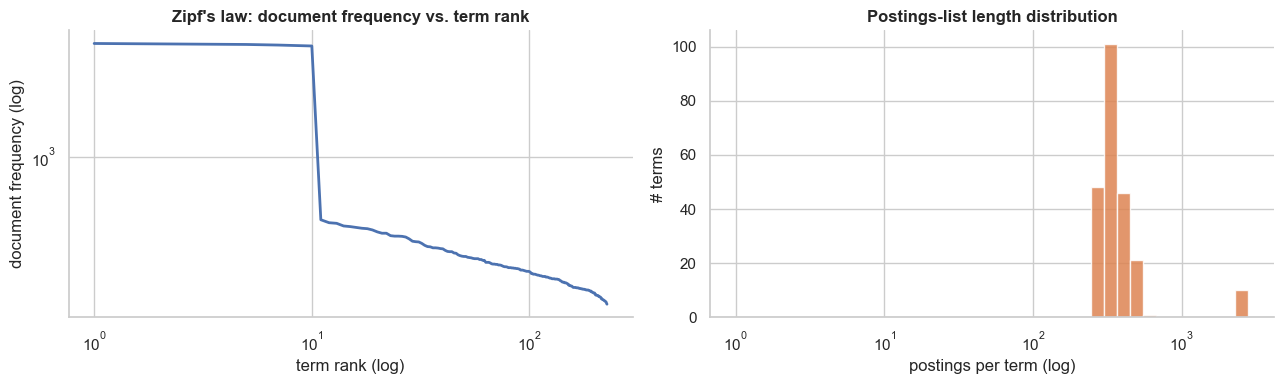

Most frequent (non-stop-word) terms: like(2802), people(2791), good(2782), time(2781), use(2777), just(2769), think(2762), work(2753), make(2747), know(2739)


In [4]:
# ============================================================
# 2. TOKENISATION, INVERTED INDEX, TF-IDF, BM25
# ============================================================
TOKEN_PATTERN = r"(?u)\b[a-zA-Z]{2,}\b"
cv = CountVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, lowercase=True, min_df=1)
X_tf = cv.fit_transform(df.text).tocsr()                 # N x V raw counts
analyzer = cv.build_analyzer()                            # same tokenizer reused everywhere
vocab = cv.vocabulary_
inv_vocab = np.array(cv.get_feature_names_out())
X_bin = (X_tf > 0).astype(np.int8).tocsc()                # presence matrix (inverted-index view)
V = len(vocab)

class BM25:
    """Okapi BM25 over a sparse count matrix. The CSC arrays are the inverted index."""
    def __init__(self, counts, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.csc = counts.tocsc().astype(np.float32)
        self.N = counts.shape[0]
        self.dl = np.asarray(counts.sum(1)).ravel().astype(np.float32)
        self.avgdl = self.dl.mean()
        n_t = np.diff(self.csc.indptr)
        self.idf = np.log(1 + (self.N - n_t + 0.5) / (n_t + 0.5)).astype(np.float32)
        self.norm = k1 * (1 - b + b * self.dl / self.avgdl)
    def postings(self, j):
        s, e = self.csc.indptr[j], self.csc.indptr[j + 1]
        return self.csc.indices[s:e], self.csc.data[s:e]
    def score(self, query):
        scores = np.zeros(self.N, dtype=np.float32)
        for t in set(analyzer(query)):
            j = vocab.get(t)
            if j is None: continue
            d, tf = self.postings(j)
            scores[d] += self.idf[j] * tf * (self.k1 + 1) / (tf + self.norm[d])
        return scores

bm25 = BM25(X_tf)                                         # default parameters, tuned later

tfidf = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, sublinear_tf=True,
                        ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=50000)
X_tfidf = tfidf.fit_transform(df.text)
def tfidf_score(q):
    return np.asarray((X_tfidf @ tfidf.transform([q]).T).todense()).ravel()

# ---- index statistics ----
nnz = X_tf.nnz
print(f"Documents N = {N:,} | vocabulary |V| = {V:,} | avg doc length = {bm25.avgdl:.1f} tokens")
print(f"Postings (non-zeros) = {nnz:,} | matrix density = {nnz / (N * V):.4%}")
j = vocab.get("space", 0)
d_ids, tfs = bm25.postings(j)
print(f"\nPostings list of the term '{inv_vocab[j]}': {len(d_ids)} docs  e.g. (doc, tf) = {list(zip(d_ids[:5].tolist(), tfs[:5].astype(int).tolist()))}")

# ---- Zipf's law & postings-length distribution ----
dfreq = np.diff(X_bin.indptr)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ranked = np.sort(dfreq)[::-1]
axes[0].loglog(np.arange(1, V + 1), ranked, color=sns.color_palette()[0], lw=2)
axes[0].set_title("Zipf's law: document frequency vs. term rank"); axes[0].set_xlabel("term rank (log)"); axes[0].set_ylabel("document frequency (log)")
axes[1].hist(dfreq, bins=np.logspace(0, np.log10(dfreq.max() + 1), 40), color=sns.color_palette()[1], alpha=.85)
axes[1].set_xscale("log"); axes[1].set_title("Postings-list length distribution"); axes[1].set_xlabel("postings per term (log)"); axes[1].set_ylabel("# terms")
plt.tight_layout(); plt.show()
top_terms = pd.DataFrame({"term": inv_vocab[np.argsort(-dfreq)[:10]], "df": np.sort(dfreq)[::-1][:10]})
print("Most frequent (non-stop-word) terms:", ", ".join(f"{t}({d})" for t, d in zip(top_terms.term, top_terms.df)))

### 6.1 Evaluation framework: queries, relevance judgements and metrics

Metrics (all computed on the **full ranking of the whole collection**):

* **P@10** – fraction of the top-10 that are relevant (grade ≥ 1).
* **nDCG@10** – graded gain $\frac{2^{rel}-1}{\log_2(i+1)}$ normalised by the ideal ordering.
* **MAP@100** – mean average precision over the top 100.
* **MRR** – reciprocal rank of the first relevant result.

In [5]:
# ============================================================
# 3. QUERIES, RELEVANCE, METRICS
# ============================================================
def query_terms(q): return [t for t in set(analyzer(q)) if t in vocab]

def term_hits(q):
    h = np.zeros(N, dtype=np.int16)
    for t in query_terms(q):
        j = vocab[t]; s, e = X_bin.indptr[j], X_bin.indptr[j + 1]
        h[X_bin.indices[s:e]] += 1
    return h

def make_query(q, cat, min_hits=1, src=-1):
    """grade 2 = same newsgroup AND contains >= min_hits query terms; grade 1 = same newsgroup; else 0."""
    same = df.category.values == cat
    rel = np.where(same, np.where(term_hits(q) >= min_hits, 2, 1), 0).astype(np.int8)
    return dict(q=q, cat=cat, rel=rel, src=src)

MANUAL = [
 ("convert image file formats gif jpeg", "comp.graphics"), ("ray tracing and 3d rendering software", "comp.graphics"),
 ("upgrading ram simm in a macintosh", "comp.sys.mac.hardware"), ("scsi hard drive for my powerbook", "comp.sys.mac.hardware"),
 ("best used car engine reliability mileage", "rec.autos"), ("brake and tire problems on my sedan", "rec.autos"),
 ("who is the best pitcher this season", "rec.sport.baseball"), ("team batting average and playoff race", "rec.sport.baseball"),
 ("clipper chip and government key escrow", "sci.crypt"), ("public key encryption and digital signatures", "sci.crypt"),
 ("symptoms and treatment of chronic infection", "sci.med"), ("diet and vitamins for health", "sci.med"),
 ("nasa shuttle launch to the moon and mars", "sci.space"), ("orbit of satellites and space telescope", "sci.space"),
 ("selling used stereo cd player asking price", "misc.forsale"), ("new in box obo shipping included", "misc.forsale")]
MANUAL_Q = [make_query(q, c, min_hits=1) for q, c in MANUAL]

# ---- automatic pseudo-queries from TEST-split documents (3 salient terms of a random document) ----
tfidf_uni = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=3, max_df=0.3)
X_uni = tfidf_uni.fit_transform(df.text)
uni_terms = np.array(tfidf_uni.get_feature_names_out())
rng = np.random.default_rng(SEED)
AUTO = []
for cat in CATS:
    pool = [i for i in test_idx if df.category[i] == cat]
    for i in rng.choice(pool, size=min(25, len(pool)), replace=False):
        row = X_uni[i].toarray().ravel(); top = np.argsort(-row)[:5]
        top = [t for t in top if row[t] > 0]
        if len(top) < 3: continue
        pick = rng.choice(top, size=3, replace=False)
        AUTO.append(make_query(" ".join(uni_terms[pick]), cat, min_hits=2, src=int(i)))
# split queries 70/30 (stratified by group): tuning / LTR-training vs. held-out test
AUTO_TRAIN, AUTO_TEST = [], []
seen = Counter()
for Q in AUTO:
    seen[Q["cat"]] += 1
    (AUTO_TRAIN if seen[Q["cat"]] <= 17 else AUTO_TEST).append(Q)
print(f"{len(MANUAL_Q)} manual queries | {len(AUTO)} automatic queries -> {len(AUTO_TRAIN)} train / {len(AUTO_TEST)} held-out test")
print("Example automatic queries:", [Q["q"] for Q in AUTO_TEST[:4]])

# ---- metrics ----
METRICS = ["P10", "nDCG10", "MAP100", "MRR"]
def dcg(r): r = np.asarray(r, float); return ((2 ** r - 1) / np.log2(np.arange(2, len(r) + 2))).sum()
def metrics_for(scores, rel):
    order = np.argsort(-scores, kind="stable")[:100]
    r = rel[order]
    ideal = np.sort(rel)[::-1][:10]
    ndcg = dcg(r[:10]) / dcg(ideal) if ideal.sum() > 0 else 0.0
    rb = r > 0; R = int((rel > 0).sum())
    ap = (np.cumsum(rb) / np.arange(1, len(r) + 1))[rb].sum() / min(R, 100) if R else 0.0
    first = np.where(rb)[0]
    return dict(P10=rb[:10].mean(), nDCG10=ndcg, MAP100=ap, MRR=1 / (first[0] + 1) if len(first) else 0.0)

def evaluate(fn, queries):
    rows = []
    for Q in queries:
        m = metrics_for(fn(Q["q"]), Q["rel"]); m["cat"] = Q["cat"]; rows.append(m)
    return pd.DataFrame(rows)

LB, PERQ = {}, {}          # leaderboard (means) and per-query results
def register(name, fn):
    """Evaluate `fn(query_text)->scores` on manual + held-out auto queries and store the results."""
    parts, out = [], {}
    for tag, qs in [("manual", MANUAL_Q), ("auto", AUTO_TEST)]:
        r = evaluate(fn, qs); r["set"] = tag; parts.append(r); out[tag] = r[METRICS].mean()
    LB[name] = out; PERQ[name] = pd.concat(parts)
    return out

def leaderboard(tag):
    return pd.DataFrame({m: LB[m][tag] for m in LB}).T.round(3)

register("TF-IDF cosine", tfidf_score)
register("BM25 (default k1=1.5,b=.75)", bm25.score)
display(leaderboard("auto"))

16 manual queries | 200 automatic queries -> 136 train / 64 held-out test
Example automatic queries: ['image keyboard animation', 'draft pixels software', 'jpeg files graphics', 'ballpark texture graphics']


,P10,nDCG10,MAP100,MRR
TF-IDF cosine,0.689,0.729,0.508,0.945
"BM25 (default k1=1.5,b=.75)",0.706,0.759,0.522,0.974


### 6.2 Tuning BM25 on the *training* queries

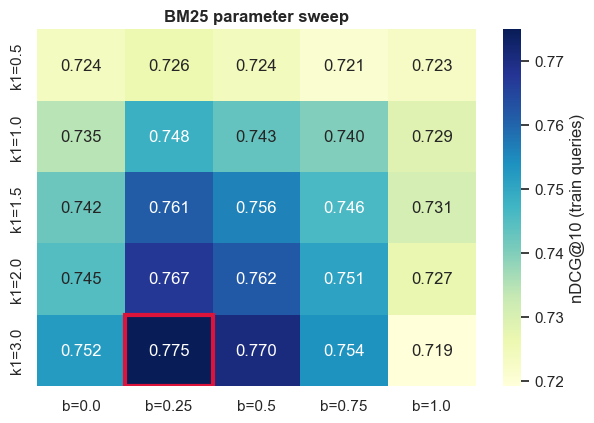

Best parameters on training queries: k1=3.0, b=0.25

Query: "clipper chip and government key escrow"
  1. [    crypt] score=15.675  Good some decrypt like also it message this series other and? Suspension the clipper pgp and wo
  2. [    crypt] score=14.111  To chip some chip key wiretap get or signature chip? As in for when payload and which this nsa 
  3. [    crypt] score=13.997  Was random as brake this some use this not from and about at good escrow their people? Or wiret
  4. [    crypt] score=13.817  Of was are been anonymous when encryption not can work interested time time? Could this about h
  5. [    crypt] score=13.666  It that think or been get work about for model is in render all or. Think get it is was to was 

Query: "upgrading ram simm in a macintosh"
  1. [ hardware] score=12.053  Work the cryptography use simm texture have mac for with other people could like! New think wor
  2. [ hardware] score=11.719  Or you this will macintosh have one or would. Work but to diet

In [6]:
# ============================================================
# 4. BM25 PARAMETER SWEEP (train queries only)
# ============================================================
k1_grid = [0.5, 1.0, 1.5, 2.0, 3.0]; b_grid = [0.0, 0.25, 0.5, 0.75, 1.0]
grid = np.zeros((len(k1_grid), len(b_grid)))
for a, k1 in enumerate(k1_grid):
    for c, b in enumerate(b_grid):
        m = BM25(X_tf, k1=k1, b=b)
        grid[a, c] = evaluate(m.score, AUTO_TRAIN)["nDCG10"].mean()
best_a, best_c = np.unravel_index(grid.argmax(), grid.shape)
K1_BEST, B_BEST = k1_grid[best_a], b_grid[best_c]

fig, ax = plt.subplots(figsize=(6.2, 4.4))
sns.heatmap(pd.DataFrame(grid, index=[f"k1={k}" for k in k1_grid], columns=[f"b={b}" for b in b_grid]),
            annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "nDCG@10 (train queries)"}, ax=ax)
ax.add_patch(plt.Rectangle((best_c, best_a), 1, 1, fill=False, ec="crimson", lw=3))
ax.set_title("BM25 parameter sweep"); plt.tight_layout(); plt.show()

bm25 = BM25(X_tf, k1=K1_BEST, b=B_BEST)
register(f"BM25 tuned (k1={K1_BEST}, b={B_BEST})", bm25.score)
print(f"Best parameters on training queries: k1={K1_BEST}, b={B_BEST}")

def show_results(q, score_fn, k=5):
    s = score_fn(q); top = np.argsort(-s)[:k]
    print(f'\nQuery: "{q}"')
    for r, i in enumerate(top, 1):
        print(f"  {r}. [{df.short[i]:>9}] score={s[i]:.3f}  {df.snippet[i][:95]}")
show_results("clipper chip and government key escrow", bm25.score)
show_results("upgrading ram simm in a macintosh", bm25.score)

## 7. Word embeddings

Lexical matching fails on **vocabulary mismatch** ("car" vs. "automobile"). Word embeddings place words with similar *contexts* close together. 

A document/query vector is the **IDF-weighted average of its word vectors**; ranking is by cosine similarity.

In [7]:
# ============================================================
# 5. WORD EMBEDDINGS
# ============================================================
class WordVectors:
    def __init__(self, words, vecs):
        self.words = list(words); self.idx = {w: i for i, w in enumerate(self.words)}
        self.vecs = normalize(np.asarray(vecs, dtype=np.float32))
    def __contains__(self, w): return w in self.idx
    def most_similar(self, w, topn=8):
        s = self.vecs @ self.vecs[self.idx[w]]
        return [(self.words[i], float(s[i])) for i in np.argsort(-s)[1:topn + 1]]

tok_docs = [analyzer(t) for t in df.text]
if HAS_GENSIM:
    from gensim.models import Word2Vec
    w2v = Word2Vec(sentences=tok_docs, vector_size=100, window=5, min_count=3, workers=2, sg=1, epochs=20, seed=SEED)
    wvs = WordVectors(w2v.wv.index_to_key, w2v.wv.vectors)
    WV_NAME = "Word2Vec skip-gram (gensim, 100-d)"
else:
    M = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, min_df=3, max_df=0.5, sublinear_tf=True)
    Xm = M.fit_transform(df.text)
    svd_w = TruncatedSVD(n_components=100, random_state=SEED).fit(Xm)
    wvs = WordVectors(M.get_feature_names_out(), svd_w.components_.T)
    WV_NAME = "LSA term vectors (SVD of TF-IDF, 100-d)  [fall-back for Word2Vec]"
print("Word-vector model:", WV_NAME, "| vocabulary:", len(wvs.words))

probe = [w for w in ["space", "car", "encryption", "pain", "image", "baseball", "mac", "price"] if w in wvs]
nn_table = pd.DataFrame({w: [f"{x}" for x, _ in wvs.most_similar(w, 6)] for w in probe}).T
nn_table.columns = [f"nn{i}" for i in range(1, 7)]
print("\nNearest neighbours in embedding space:"); display(nn_table)

# ---- document / query vectors = IDF-weighted average of word vectors ----
idf_vec = bm25.idf.astype(np.float32)
W = np.zeros((V, wvs.vecs.shape[1]), dtype=np.float32)
for w, j in vocab.items():
    i = wvs.idx.get(w)
    if i is not None: W[j] = wvs.vecs[i]
doc_wv = normalize(sp.csr_matrix(X_tf.multiply(idf_vec)) @ W).astype(np.float32)
def wv_embed_query(q): return normalize(sp.csr_matrix(cv.transform([q]).multiply(idf_vec)) @ W)[0]
def wv_score(q): return doc_wv @ wv_embed_query(q)
register("Word-embedding avg", wv_score)

Word-vector model: LSA term vectors (SVD of TF-IDF, 100-d)  [fall-back for Word2Vec] | vocabulary: 217

Nearest neighbours in embedding space:


,nn1,nn2,nn3,nn4,nn5,nn6
space,earth,flight,ray,convertible,payload,launch
car,driving,video,gas,bmw,model,hospital
encryption,message,secure,privacy,palette,random,signature
pain,slot,solar,display,doctor,clipper,manager
image,ray,viewer,resolution,software,shader,vehicle
baseball,yankees,average,visualization,ballpark,software,runs
mac,modem,simm,scsi,adapter,upgrade,secure
price,pitch,ray,strikeout,software,probe,message


{'manual': P10       0.993750
 nDCG10    0.994076
 MAP100    0.985324
 MRR       1.000000
 dtype: float64,
 'auto': P10       0.721875
 nDCG10    0.727239
 MAP100    0.558145
 MRR       0.909102
 dtype: float64}

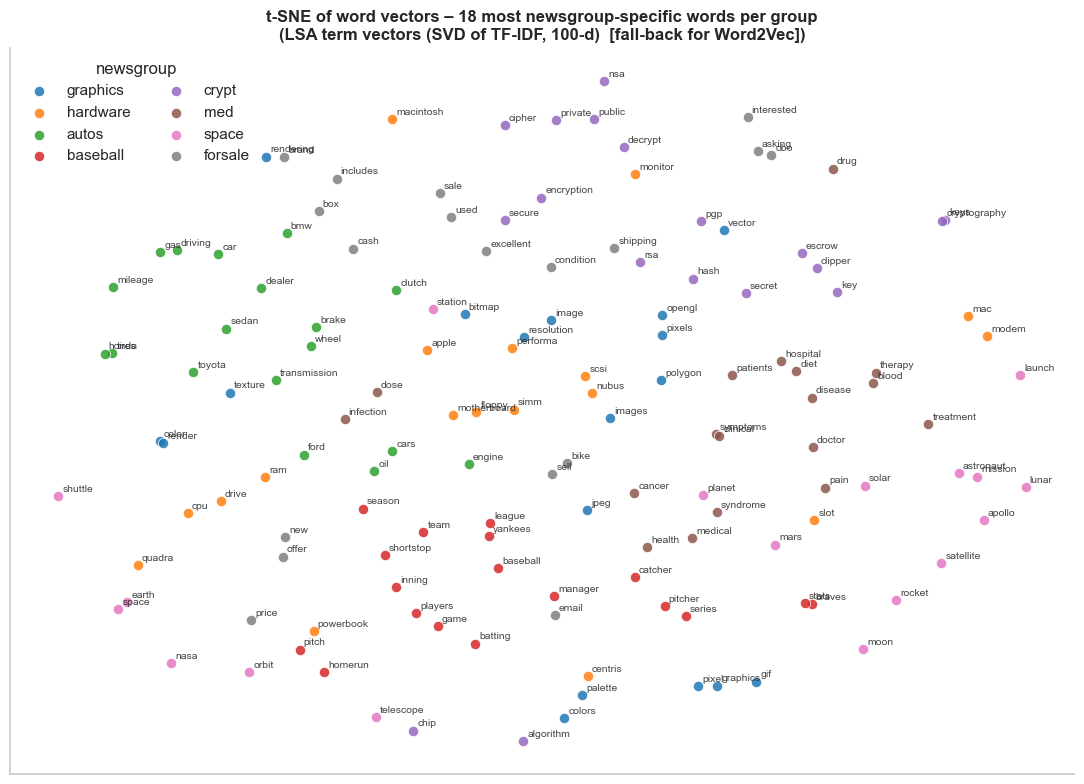

In [8]:
# ============================================================
# 5b. VISUALISING THE WORD SPACE (t-SNE of category-specific words)
# ============================================================
Xb = X_bin.tocsr()
cat_df = np.vstack([np.asarray((Xb[df.category.values == c] > 0).mean(0)).ravel() for c in CATS])   # (8, V)
purity = cat_df / (cat_df.sum(0) + 1e-9)
doc_freq = np.diff(X_bin.indptr)
sel, sel_cat = [], []
for ci, c in enumerate(CATS):
    cand = [j for j in np.argsort(-(purity[ci] * np.log1p(doc_freq))) if doc_freq[j] >= 15 and inv_vocab[j] in wvs][:18]
    sel += cand; sel_cat += [c] * len(cand)
Wsel = np.vstack([wvs.vecs[wvs.idx[inv_vocab[j]]] for j in sel])
xy = TSNE(n_components=2, perplexity=min(25, len(sel) // 4), init="pca", random_state=SEED, learning_rate="auto").fit_transform(Wsel)

fig, ax = plt.subplots(figsize=(11, 8))
for c in CATS:
    m = np.array(sel_cat) == c
    ax.scatter(xy[m, 0], xy[m, 1], s=55, color=CAT_PAL[c], label=SHORT[c], alpha=.85, edgecolor="white", lw=.6)
for (x, y), j in zip(xy, sel):
    ax.annotate(inv_vocab[j], (x, y), fontsize=7.5, xytext=(3, 3), textcoords="offset points", alpha=.85)
ax.set_title(f"t-SNE of word vectors – 18 most newsgroup-specific words per group\n({WV_NAME})")
ax.legend(title="newsgroup", ncol=2, loc="best"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 8. Neural information retrieval: BERT bi-encoder + FAISS, hybrid fusion and cross-encoder re-ranking

**Dense retrieval.** A **Sentence-BERT bi-encoder** (`all-MiniLM-L6-v2`) maps every post and every query to a 384-d vector; relevance ≈ cosine similarity. Because documents are encoded *offline*, query time is one forward pass plus a nearest-neighbour search (**FAISS**).

**Hybrid retrieval.** Lexical (BM25) and dense scores are complementary: BM25 is precise for rare keywords, dense retrieval handles paraphrase. We fuse them with **Reciprocal Rank Fusion** (Cormack et al., 2009) $\text{RRF}(d)=\sum_r \frac{1}{60+\text{rank}_r(d)}$ and with a tuned linear combination of min–max-normalised scores.

**Cross-encoder re-ranking.** A BERT **cross-encoder** reads (query, document) *together* – far more accurate, but too slow for the whole collection – so it only re-orders the top-30 candidates.


In [ ]:
# ============================================================
# 6. DENSE ENCODER (SBERT) + INDEX
# ============================================================
DENSE_NAME = None
if HAS_ST:
    try:
        from sentence_transformers import SentenceTransformer
        st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2"); st_model.max_seq_length = 256
        def encode_texts(txts, bs=64):
            return st_model.encode(list(txts), batch_size=bs, normalize_embeddings=True,
                                   show_progress_bar=len(txts) > 500).astype("float32")
        DENSE_NAME = "Sentence-BERT all-MiniLM-L6-v2 (384-d)"
    except Exception as e:
        print("Could not load SBERT ->", type(e).__name__, "; using LSA fall-back"); HAS_ST = False
if not HAS_ST:
    svd = TruncatedSVD(n_components=256, random_state=SEED).fit(X_tfidf)
    def encode_texts(txts, bs=None):
        return normalize(svd.transform(tfidf.transform(list(txts)))).astype("float32")
    DENSE_NAME = "LSA-256 (TF-IDF → truncated SVD)  [fall-back for SBERT]"

t0 = time.time(); doc_emb = encode_texts(df.text); enc_time = time.time() - t0
print(f"Dense encoder: {DENSE_NAME}\nEncoded {N:,} docs -> {doc_emb.shape} in {enc_time:.1f}s")

def dense_score(q): return doc_emb @ encode_texts([q])[0]
register("Dense (" + ("SBERT" if HAS_ST else "LSA") + ")", dense_score)

# ---------- ANN search with FAISS (exact vs approximate HNSW) ----------
if HAS_FAISS:
    import faiss
    d = doc_emb.shape[1]
    flat = faiss.IndexFlatIP(d); flat.add(doc_emb)
    hnsw = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT); hnsw.hnsw.efConstruction = 80; hnsw.add(doc_emb)
    Qemb = encode_texts([Q["q"] for Q in AUTO])
    t = time.time(); _, I_flat = flat.search(Qemb, 10); t_flat = time.time() - t
    t = time.time(); _, I_h = hnsw.search(Qemb, 10); t_h = time.time() - t
    rec = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(I_flat, I_h)])
    print(f"FAISS Flat: {t_flat * 1e3:.1f} ms for {len(Qemb)} queries | HNSW: {t_h * 1e3:.1f} ms | HNSW recall@10 vs exact = {rec:.3f}")
else:
    print("FAISS not installed -> exact search via numpy matrix product (same results, fine for ~4k docs).")

Dense encoder: LSA-256 (TF-IDF → truncated SVD)  [fall-back for SBERT]
Encoded 4,000 docs -> (4000, 256) in 1.5s
FAISS Flat: 22.4 ms for 200 queries | HNSW: 10.1 ms | HNSW recall@10 vs exact = 0.853


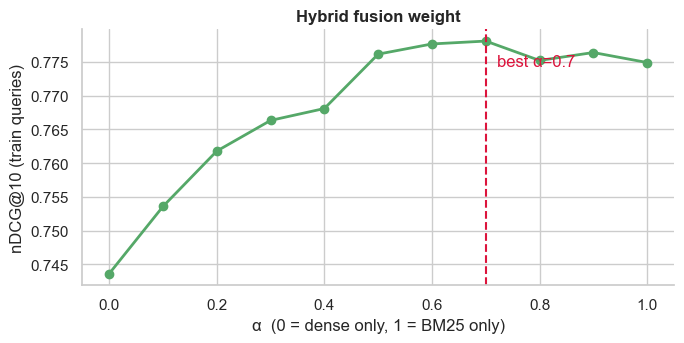

Cross-encoder re-ranking skipped (needs sentence-transformers); learning-to-rank in §13 plays the re-ranker role.


In [ ]:
# ============================================================
# 7. HYBRID FUSION + CROSS-ENCODER
# ============================================================
def _rank(s): return np.argsort(np.argsort(-s, kind="stable"), kind="stable")
def minmax(s): return (s - s.min()) / (s.max() - s.min() + 1e-9)
def rrf_fuse(score_list, k=60):
    out = np.zeros(N)
    for s in score_list: out += 1.0 / (k + _rank(s) + 1)
    return out
def lin_fuse(sa, sb, alpha): return alpha * minmax(sa) + (1 - alpha) * minmax(sb)

# tune alpha on TRAIN queries
alphas = np.linspace(0, 1, 11); curve = []
for a in alphas:
    f = lambda q, a=a: lin_fuse(bm25.score(q), dense_score(q), a)
    curve.append(evaluate(f, AUTO_TRAIN)["nDCG10"].mean())
ALPHA = float(alphas[int(np.argmax(curve))])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(alphas, curve, marker="o", color=sns.color_palette()[2], lw=2)
ax.axvline(ALPHA, ls="--", color="crimson"); ax.annotate(f"best α={ALPHA:.1f}", (ALPHA, max(curve)), xytext=(8, -18), textcoords="offset points", color="crimson")
ax.set_xlabel("α  (0 = dense only, 1 = BM25 only)"); ax.set_ylabel("nDCG@10 (train queries)"); ax.set_title("Hybrid fusion weight")
plt.tight_layout(); plt.show()

hybrid_rrf = lambda q: rrf_fuse([bm25.score(q), dense_score(q)])
hybrid_lin = lambda q: lin_fuse(bm25.score(q), dense_score(q), ALPHA)
register("Hybrid RRF (BM25+dense)", hybrid_rrf)
register(f"Hybrid linear (α={ALPHA:.1f})", hybrid_lin)

# ---------- cross-encoder re-ranking of the top-30 ----------
CE_OK = False
if HAS_ST:
    try:
        from sentence_transformers import CrossEncoder
        ce = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", max_length=256); CE_OK = True
    except Exception as e:
        print("Cross-encoder unavailable ->", type(e).__name__)
if CE_OK:
    def hybrid_ce(q, k=30):
        base = hybrid_lin(q); top = np.argsort(-base)[:k]
        sc = ce.predict([(q, df.text[i][:1200]) for i in top], show_progress_bar=False)
        out = base - base.max() - 1.0; out[top] = 1000 + sc
        return out
    register("Hybrid + BERT cross-encoder (top-30)", hybrid_ce)
else:
    print("Cross-encoder re-ranking skipped (needs sentence-transformers); learning-to-rank in 13 plays the re-ranker role.")

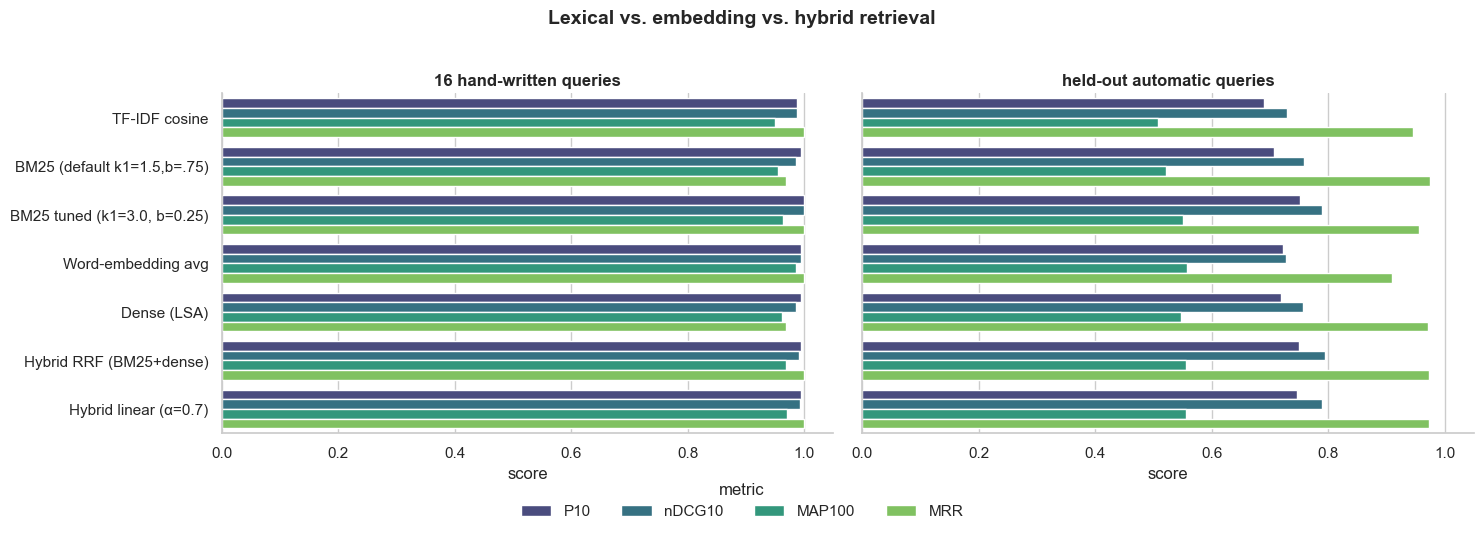

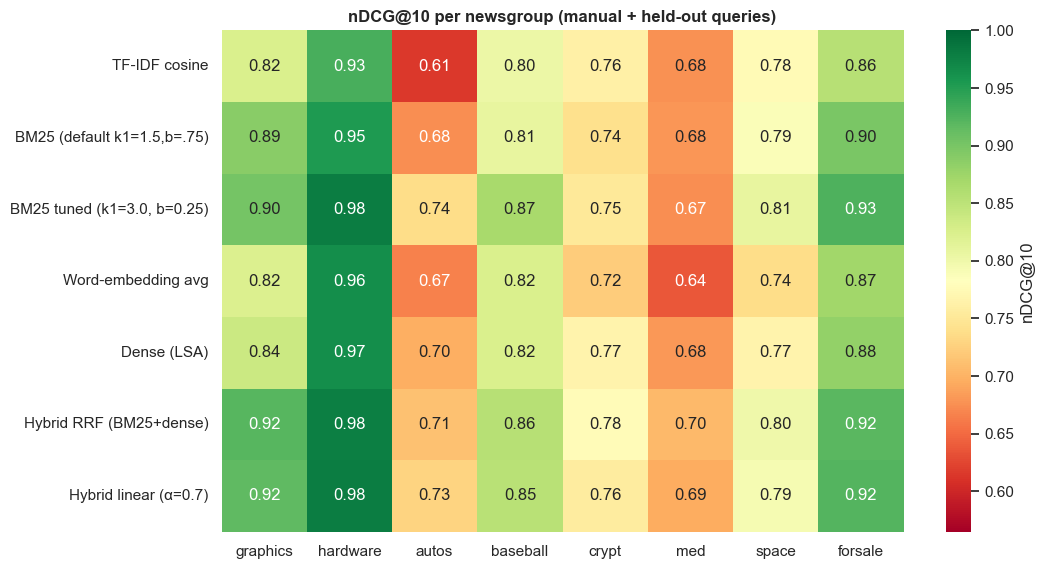

Held-out automatic queries:


,P10,nDCG10,MAP100,MRR
TF-IDF cosine,0.689,0.729,0.508,0.945
"BM25 (default k1=1.5,b=.75)",0.706,0.759,0.522,0.974
"BM25 tuned (k1=3.0, b=0.25)",0.752,0.789,0.550,0.956
Word-embedding avg,0.722,0.727,0.558,0.909
Dense (LSA),0.719,0.756,0.547,0.971
Hybrid RRF (BM25+dense),0.750,0.794,0.556,0.972
Hybrid linear (α=0.7),0.747,0.790,0.556,0.972


Manual queries:


,P10,nDCG10,MAP100,MRR
TF-IDF cosine,0.988,0.987,0.949,1.000
"BM25 (default k1=1.5,b=.75)",0.994,0.986,0.955,0.969
"BM25 tuned (k1=3.0, b=0.25)",1.000,1.000,0.964,1.000
Word-embedding avg,0.994,0.994,0.985,1.000
Dense (LSA),0.994,0.986,0.962,0.969
Hybrid RRF (BM25+dense),0.994,0.991,0.968,1.000
Hybrid linear (α=0.7),0.994,0.993,0.971,1.000


In [11]:
# ============================================================
# 8. COMPARISON PLOTS
# ============================================================
def plot_leaderboard(title="Retrieval effectiveness"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    for ax, (tag, name) in zip(axes, [("manual", "16 hand-written queries"), ("auto", "held-out automatic queries")]):
        lb = leaderboard(tag).reset_index().rename(columns={"index": "method"}).melt("method", var_name="metric", value_name="score")
        sns.barplot(data=lb, y="method", x="score", hue="metric", ax=ax, palette="viridis", order=list(LB))
        ax.set_title(name); ax.set_xlim(0, 1.05); ax.set_ylabel(""); ax.set_xlabel("score")
        if ax is axes[0]: handles, labels_ = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    fig.legend(handles, labels_, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.07), title="metric")
    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.02); plt.tight_layout(); plt.show()

def plot_per_category(methods=None):
    allq = pd.concat([PERQ[m].assign(method=m) for m in (methods or LB)])
    pv = allq.groupby(["method", "cat"])["nDCG10"].mean().unstack().reindex(list(methods or LB))[CATS]
    pv.columns = [SHORT[c] for c in pv.columns]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(pv) + 2))
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="RdYlGn", vmin=max(0, pv.values.min() - .05), vmax=1, ax=ax, cbar_kws={"label": "nDCG@10"})
    ax.set_title("nDCG@10 per newsgroup (manual + held-out queries)"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

plot_leaderboard("Lexical vs. embedding vs. hybrid retrieval")
plot_per_category()
print("Held-out automatic queries:"); display(leaderboard("auto"))
print("Manual queries:"); display(leaderboard("manual"))
RESULTS["retrieval_after_neural"] = leaderboard("auto")

In [12]:
# ============================================================
# 9. QUALITATIVE EXAMPLE – a paraphrase query where lexical matching is not enough
# ============================================================
q = "protecting my messages from government eavesdropping"
for name, fn in [("BM25", bm25.score), ("Dense", dense_score), ("Hybrid", hybrid_lin)]:
    s = fn(q); top = np.argsort(-s)[:5]
    print(f"{name:7s}->", " | ".join(f"{df.short[i]}" for i in top))

BM25   -> crypt | crypt | crypt | crypt | crypt
Dense  -> med | hardware | crypt | crypt | crypt
Hybrid -> crypt | crypt | hardware | crypt | crypt


## 9. Dimensionality reduction, clustering-based retrieval and duplicate detection

* **PCA** gives a linear, variance-preserving projection; **t-SNE** preserves *local neighbourhoods* and is the standard tool for looking at embedding clusters.
* **k-means** on document embeddings groups posts that discuss the same thing. We measure cluster quality *externally* (ARI, NMI, purity against the newsgroup labels) and *internally* (silhouette).
* **Clustering-based retrieval (cluster pruning / IVF idea):** at query time only scan the documents of the `n_probe` clusters whose centroids are closest to the query. This trades a little accuracy for a large reduction in work – the idea behind inverted-file ANN indexes.
* **Near-duplicate detection:** cross-posted or re-posted messages should be grouped so results are not repetitive.

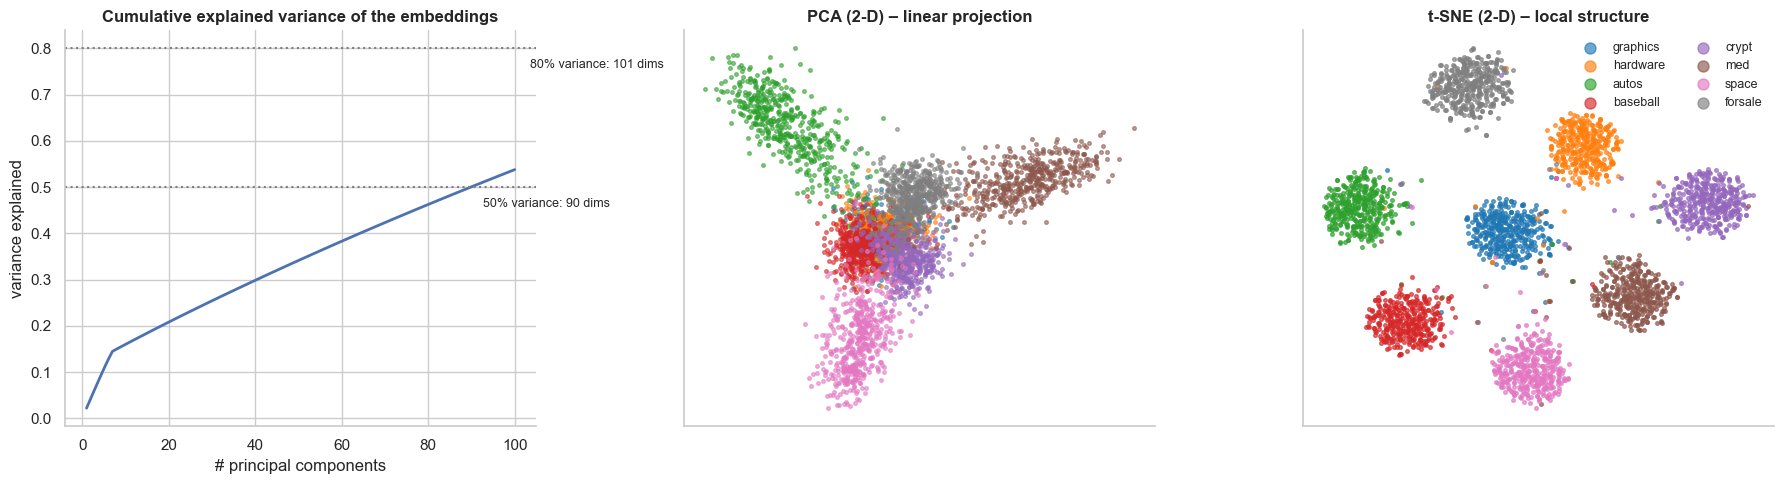

In [13]:
# ============================================================
# 10. DIMENSIONALITY REDUCTION: PCA scree, PCA map, t-SNE map
# ============================================================
pca_full = PCA(n_components=min(100, doc_emb.shape[1]), random_state=SEED).fit(doc_emb)
cum = np.cumsum(pca_full.explained_variance_ratio_)
pca2 = PCA(n_components=2, random_state=SEED).fit_transform(doc_emb)
pre = PCA(n_components=50, random_state=SEED).fit_transform(doc_emb)
TS_N = min(N, 3000)
ts_idx = np.random.default_rng(SEED).choice(N, TS_N, replace=False)
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(pre[ts_idx])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(np.arange(1, len(cum) + 1), cum, color=sns.color_palette()[0], lw=2)
for thr in (0.5, 0.8):
    k = int(np.searchsorted(cum, thr)) + 1
    axes[0].axhline(thr, ls=":", color="gray"); axes[0].annotate(f"{int(thr*100)}% variance: {k} dims", (k, thr), xytext=(8, -14), textcoords="offset points", fontsize=9)
axes[0].set_title("Cumulative explained variance of the embeddings"); axes[0].set_xlabel("# principal components"); axes[0].set_ylabel("variance explained")
for c in CATS:
    m = df.category.values == c
    axes[1].scatter(pca2[m, 0], pca2[m, 1], s=7, color=CAT_PAL[c], alpha=.55, label=SHORT[c])
    mt = df.category.values[ts_idx] == c
    axes[2].scatter(tsne_xy[mt, 0], tsne_xy[mt, 1], s=7, color=CAT_PAL[c], alpha=.65, label=SHORT[c])
axes[1].set_title("PCA (2-D) – linear projection"); axes[2].set_title("t-SNE (2-D) – local structure")
for a in axes[1:]: a.set_xticks([]); a.set_yticks([])
axes[2].legend(markerscale=3, ncol=2, fontsize=9, loc="best")
plt.tight_layout(); plt.show()

if HAS_PLOTLY:      # interactive map: hover to read the post
    import plotly.express as px
    pdf = pd.DataFrame({"x": tsne_xy[:, 0], "y": tsne_xy[:, 1], "newsgroup": df.short.values[ts_idx], "post": df.snippet.values[ts_idx]})
    fig_i = px.scatter(pdf, x="x", y="y", color="newsgroup", hover_data={"post": True, "x": False, "y": False},
                       title="Interactive t-SNE map of the archive (hover to read a post)", width=900, height=620, opacity=.75)
    fig_i.update_traces(marker=dict(size=5)); fig_i.update_xaxes(visible=False); fig_i.update_yaxes(visible=False)
    fig_i.show()

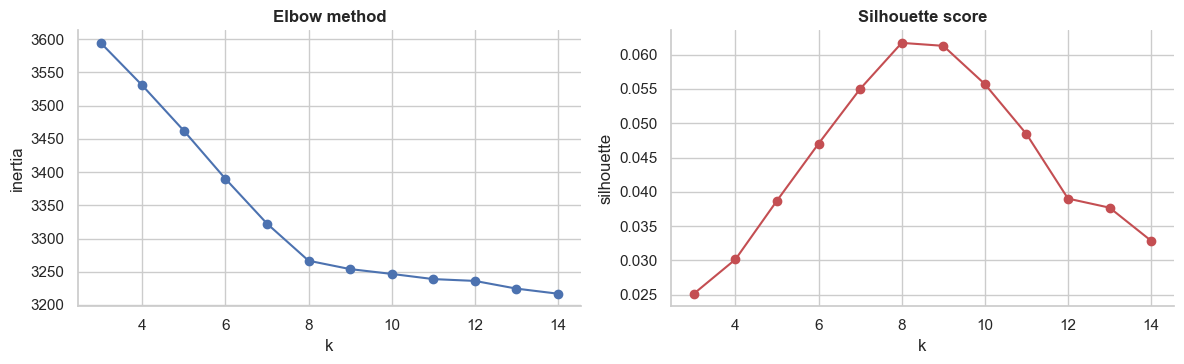

{'ARI': 0.968, 'NMI': 0.955, 'Purity': 0.986, 'Silhouette': 0.062}


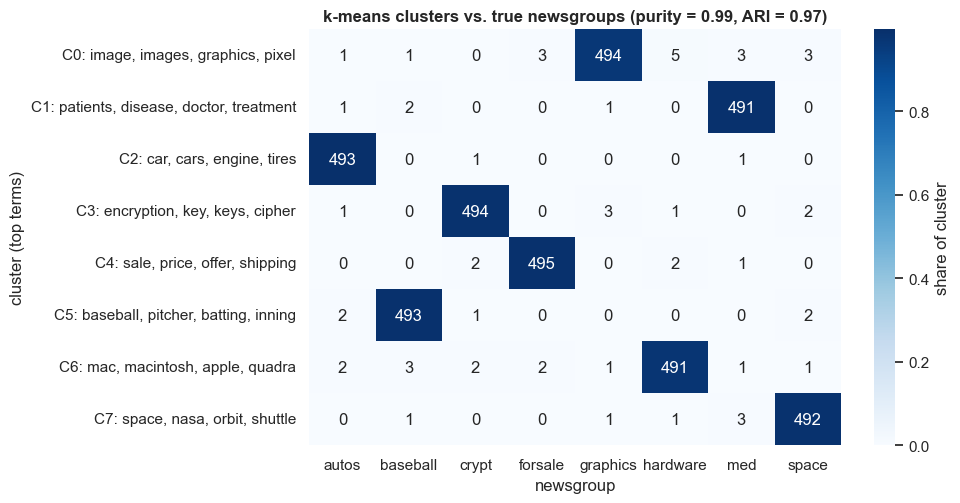

In [14]:
# ============================================================
# 11. K-MEANS CLUSTERING  (choice of k, quality, cluster x newsgroup heat-map)
# ============================================================
ks = list(range(3, 15)); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=4, random_state=SEED).fit(doc_emb)
    inertia.append(km.inertia_); sil.append(silhouette_score(doc_emb, km.labels_, sample_size=min(2000, N), random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks, inertia, marker="o", color=sns.color_palette()[0]); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(ks, sil, marker="o", color=sns.color_palette()[3]); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
plt.tight_layout(); plt.show()

K_CL = len(CATS)
km8 = KMeans(n_clusters=K_CL, n_init=10, random_state=SEED).fit(doc_emb)
cluster8 = km8.labels_
ct = pd.crosstab(cluster8, df.short)
purity_score = ct.max(1).sum() / N
RESULTS["cluster"] = dict(ARI=adjusted_rand_score(df.category, cluster8), NMI=normalized_mutual_info_score(df.category, cluster8),
                          Purity=purity_score, Silhouette=silhouette_score(doc_emb, cluster8, sample_size=min(2000, N), random_state=SEED))
print({k: round(v, 3) for k, v in RESULTS["cluster"].items()})

# describe clusters by their top TF-IDF terms
terms_of_cluster = {}
for c in range(K_CL):
    mean_vec = np.asarray(X_uni[cluster8 == c].mean(0)).ravel()
    terms_of_cluster[c] = ", ".join(uni_terms[np.argsort(-mean_vec)[:4]])
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(ct.div(ct.sum(1), axis=0), annot=ct.values, fmt="d", cmap="Blues", ax=ax, cbar_kws={"label": "share of cluster"})
ax.set_yticklabels([f"C{c}: {terms_of_cluster[c]}" for c in range(K_CL)], rotation=0)
ax.set_title(f"k-means clusters vs. true newsgroups (purity = {purity_score:.2f}, ARI = {RESULTS['cluster']['ARI']:.2f})")
ax.set_xlabel("newsgroup"); ax.set_ylabel("cluster (top terms)"); plt.tight_layout(); plt.show()

,n_probe,nDCG10,docs_scanned,ms_per_query
0,1,0.729,0.025,43.961
1,2,0.758,0.051,42.429
2,3,0.770,0.077,40.427
3,5,0.767,0.126,43.977
4,8,0.761,0.200,50.006
5,12,0.751,0.299,52.789
6,20,0.746,0.497,48.391
7,40,0.748,1.000,50.564


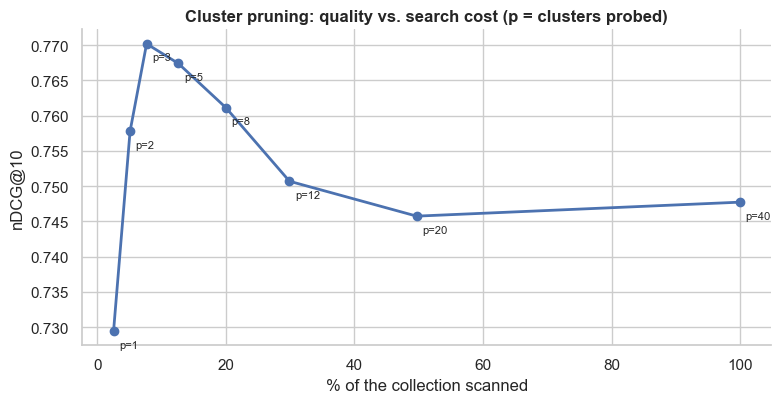

In [15]:
# ============================================================
# 12. CLUSTER-PRUNED (CLUSTERING-BASED) RETRIEVAL: accuracy vs. work
# ============================================================
N_CENT = 40
km_big = KMeans(n_clusters=N_CENT, n_init=3, random_state=SEED).fit(doc_emb)
cl_lab = km_big.labels_; centroids = normalize(km_big.cluster_centers_).astype(np.float32)

def pruned_dense(q, n_probe):
    qv = encode_texts([q])[0]
    probe = np.argsort(-(centroids @ qv))[:n_probe]
    mask = np.isin(cl_lab, probe)
    s = np.full(N, -1e3, dtype=np.float32); s[mask] = doc_emb[mask] @ qv
    return s, mask.mean()

rows = []
for n_probe in [1, 2, 3, 5, 8, 12, 20, N_CENT]:
    nd, frac, lat = [], [], []
    for Q in AUTO:
        t = time.perf_counter(); s, f = pruned_dense(Q["q"], n_probe); lat.append(time.perf_counter() - t)
        nd.append(metrics_for(s, Q["rel"])["nDCG10"]); frac.append(f)
    rows.append(dict(n_probe=n_probe, nDCG10=np.mean(nd), docs_scanned=np.mean(frac), ms_per_query=1e3 * np.mean(lat)))
prune = pd.DataFrame(rows); display(prune.round(3))
RESULTS["pruning"] = prune

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(prune.docs_scanned * 100, prune.nDCG10, marker="o", lw=2, color=sns.color_palette()[0])
for _, r in prune.iterrows(): ax.annotate(f"p={int(r.n_probe)}", (r.docs_scanned * 100, r.nDCG10), xytext=(4, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("% of the collection scanned"); ax.set_ylabel("nDCG@10"); ax.set_title("Cluster pruning: quality vs. search cost (p = clusters probed)")
plt.tight_layout(); plt.show()

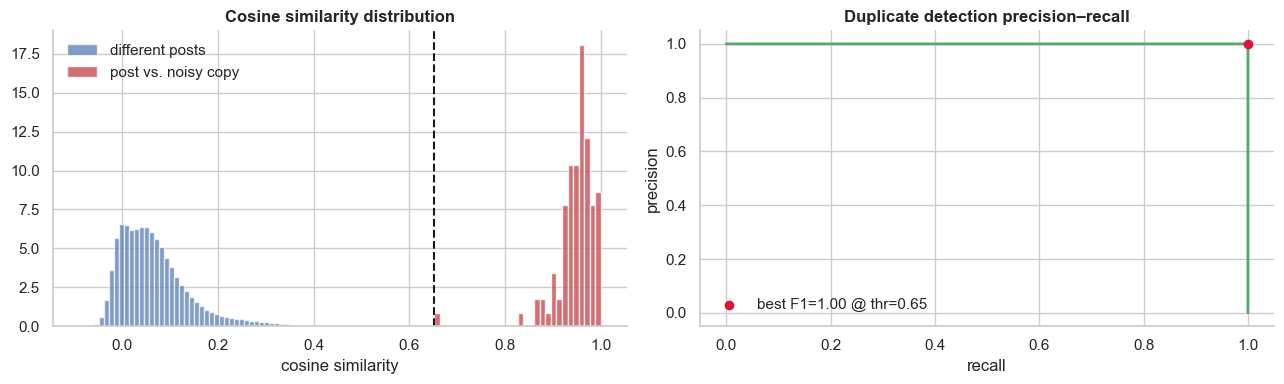

Threshold 0.652: 0 groups of near-duplicate / cross-posted posts covering 0 posts (0.0% of the archive)


In [16]:
# ============================================================
# 13. NEAR-DUPLICATE DETECTION (embedding similarity + connected components)
# ============================================================
def perturb(text, rng, drop=0.12, swaps=3):
    w = text.split()
    w = [x for x in w if rng.random() > drop]
    for _ in range(swaps):
        if len(w) > 3:
            i = int(rng.integers(0, len(w) - 1)); w[i], w[i + 1] = w[i + 1], w[i]
    return " ".join(w)

rng = np.random.default_rng(SEED)
S = rng.choice(N, size=min(800, N), replace=False)
D_pos = rng.choice(len(S), size=min(100, len(S)), replace=False)             # positions in S that get a noisy copy
copies = [perturb(df.text[S[p]], rng) for p in D_pos]
E = np.vstack([doc_emb[S], encode_texts(copies)])
M_ = len(E); sim = E @ E.T
iu = np.triu_indices(M_, 1)
lab = np.zeros((M_, M_), dtype=bool)
for j, p in enumerate(D_pos): lab[p, len(S) + j] = True
y_true, y_sim = lab[iu], sim[iu]
prec, rec, thr = precision_recall_curve(y_true, y_sim)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = int(np.argmax(f1[:-1])); THR_DUP = float(thr[best])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y_sim[~y_true], bins=60, alpha=.7, label="different posts", color=sns.color_palette()[0], density=True)
axes[0].hist(y_sim[y_true], bins=30, alpha=.8, label="post vs. noisy copy", color=sns.color_palette()[3], density=True)
axes[0].axvline(THR_DUP, color="k", ls="--"); axes[0].set_title("Cosine similarity distribution"); axes[0].set_xlabel("cosine similarity"); axes[0].legend()
axes[1].plot(rec, prec, color=sns.color_palette()[2], lw=2); axes[1].scatter(rec[best], prec[best], color="crimson", zorder=5, label=f"best F1={f1[best]:.2f} @ thr={THR_DUP:.2f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Duplicate detection precision–recall"); axes[1].legend()
plt.tight_layout(); plt.show()
RESULTS["dedup_F1"] = float(f1[best])

# apply on the whole corpus
Sfull = doc_emb @ doc_emb.T; np.fill_diagonal(Sfull, 0)
n_comp, comp = connected_components(sp.csr_matrix(Sfull >= THR_DUP), directed=False)
sizes = np.bincount(comp); dup_groups = [g for g in range(n_comp) if sizes[g] > 1]
print(f"Threshold {THR_DUP:.3f}: {len(dup_groups)} groups of near-duplicate / cross-posted posts "
      f"covering {int(sizes[dup_groups].sum()) if dup_groups else 0} posts ({(sizes[dup_groups].sum() / N if dup_groups else 0):.1%} of the archive)")
if dup_groups:
    g = max(dup_groups, key=lambda x: sizes[x]); mem = np.where(comp == g)[0][:3]
    print(f"Largest group ({sizes[g]} posts), first members:")
    for i in mem: print("  •", df.short[i], "|", df.snippet[i][:100])
del Sfull

## 11. Feature engineering, classification, ensembles and classification-based retrieval

**Feature engineering.** Beyond TF-IDF words we compute *stylistic / structural* features per post – length, average word length, upper-case ratio, digit ratio, punctuation ratio, `!` and `?` rate, `$` signs, URLs, e-mail addresses, type–token ratio, number of lines, ALL-CAPS words. They are cheap, interpretable and help both the classifier and the anomaly detector.

**Models and ensembles** (two *feature views* for diversity):

| view | features | models |
|---|---|---|
| sparse | TF-IDF (1–2 grams) + style | Naive Bayes · Logistic Regression · calibrated Linear SVM |
| dense | embeddings + style | **MLP neural network** · Extra-Trees |

Ensembles: **soft voting** (average probabilities) and **stacking** (a meta-learner trained on out-of-fold probabilities).

**Classification-based retrieval.** We classify the *query* into a newsgroup and use that to (a) **filter** the ranking to documents of the predicted group, or (b) **boost** documents proportionally to $\sum_c P(c|q)P(c|d)$.

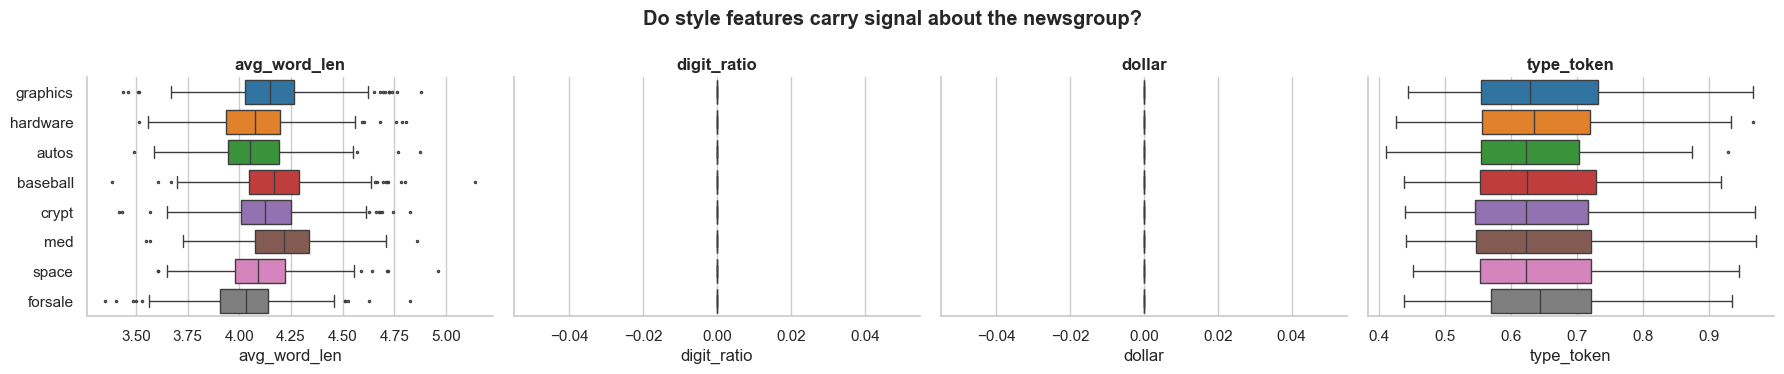

In [18]:
# ============================================================
# 15. FEATURE ENGINEERING
# ============================================================
def style_features(t):
    n = len(t) + 1e-9
    words = re.findall(r"[A-Za-z']+", t); nw = len(words) + 1e-9
    return dict(
        log_chars=np.log1p(len(t)), log_words=np.log1p(len(words)),
        avg_word_len=float(np.mean([len(w) for w in words])) if words else 0.0,
        upper_ratio=sum(c.isupper() for c in t) / n, digit_ratio=sum(c.isdigit() for c in t) / n,
        punct_ratio=sum(c in string.punctuation for c in t) / n, excl_rate=t.count("!") / nw, quest_rate=t.count("?") / nw,
        dollar=t.count("$"), n_urls=len(re.findall(r"http\S+|www\.\S+", t)), n_emails=len(re.findall(r"\S+@\S+", t)),
        type_token=len({w.lower() for w in words}) / nw, log_lines=np.log1p(t.count("\n")),
        caps_words=sum(w.isupper() and len(w) > 1 for w in words) / nw)

STY = pd.DataFrame([style_features(t) for t in df.raw]); STY_COLS = list(STY.columns)
show = ["avg_word_len", "digit_ratio", "dollar", "type_token"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for a, f in zip(axes, show):
    sns.boxplot(data=pd.DataFrame({"short": df.short, f: STY[f]}), y="short", x=f, order=order, palette=[CAT_PAL[c] for c in CATS], ax=a, fliersize=1.5)
    a.set_title(f); a.set_ylabel("")
    if a is not axes[0]: a.set_yticklabels([])
fig.suptitle("Do style features carry signal about the newsgroup?", fontweight="bold"); plt.tight_layout(); plt.show()

,model,accuracy,macro_F1
0,Linear SVM (calibrated),0.987,0.987
1,ENSEMBLE: stacking,0.986,0.986
2,Logistic Regression,0.986,0.986
3,ENSEMBLE: soft voting,0.984,0.984
4,Extra-Trees (embeddings),0.981,0.981
5,Naive Bayes,0.977,0.977
6,MLP neural net (embeddings),0.973,0.973


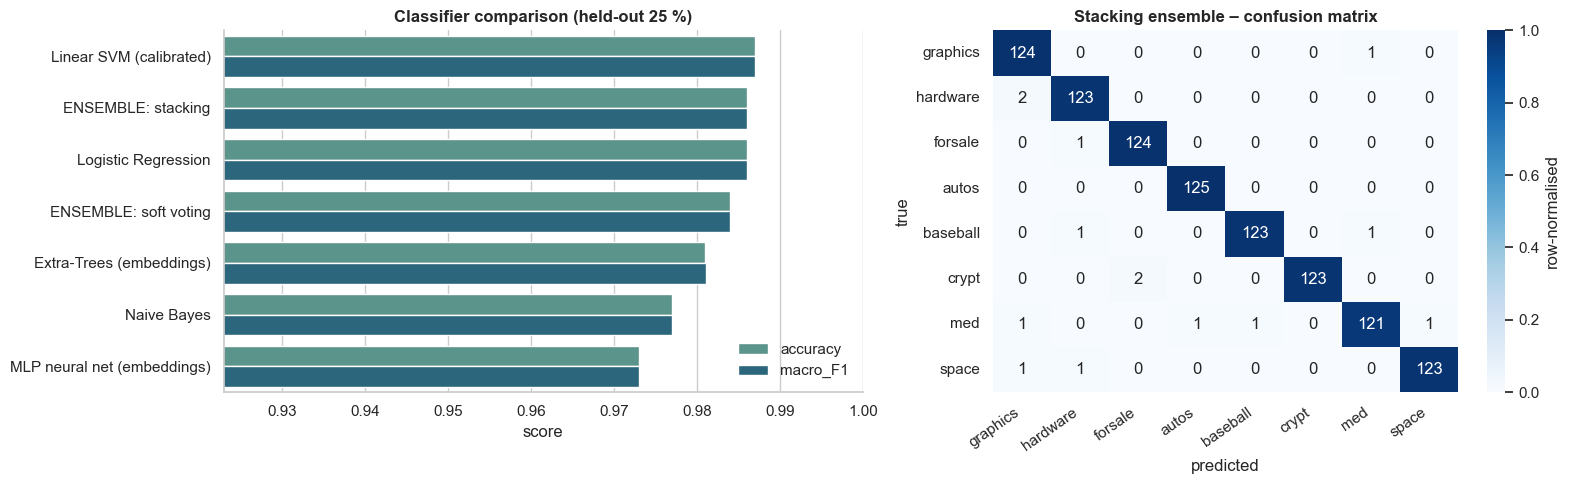

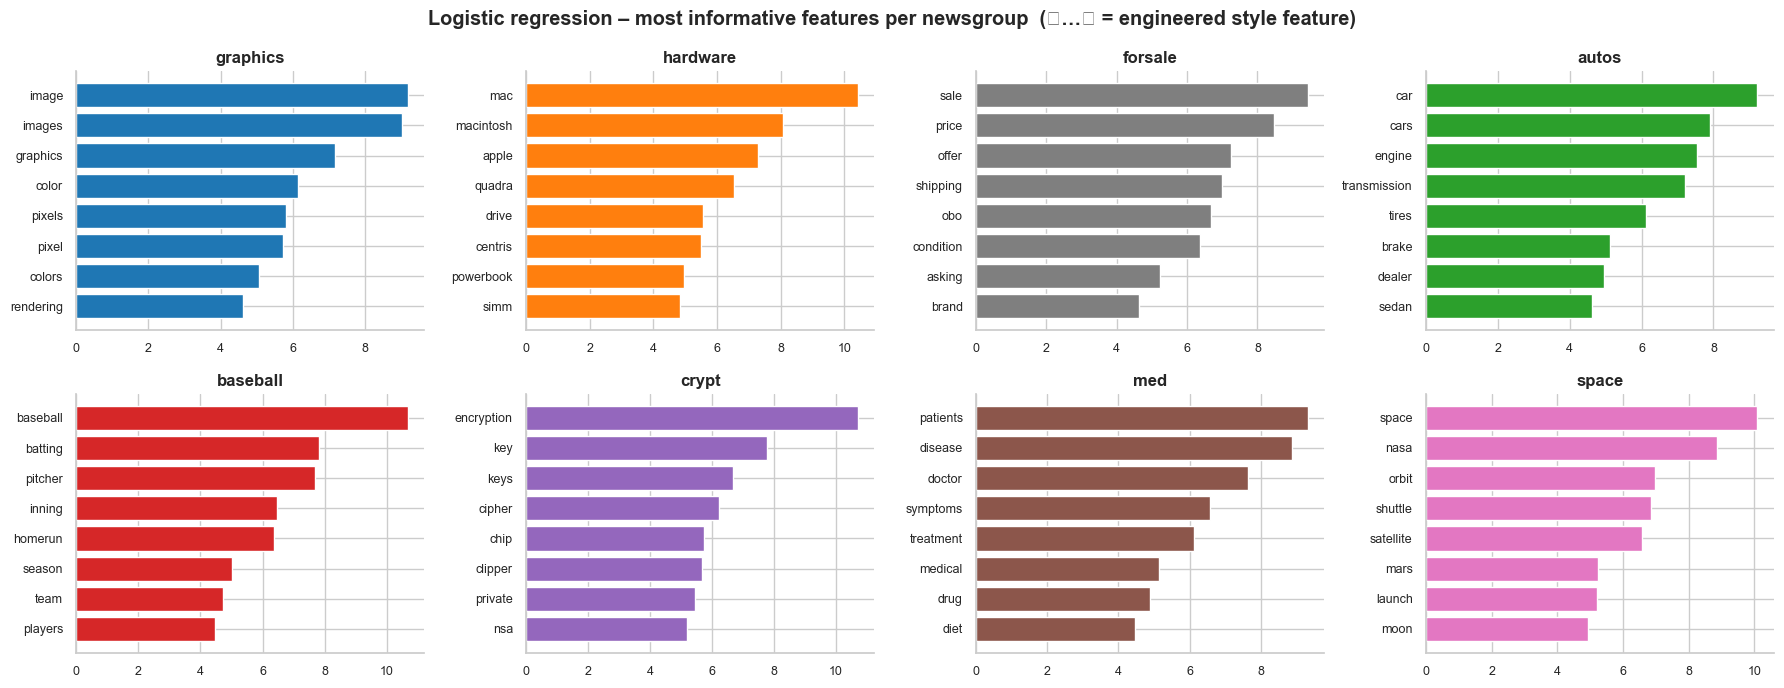

Feature-engineering ablation (Logistic Regression):


,features,accuracy,macro_F1
0,TF-IDF only,0.989,0.989
1,TF-IDF + style,0.986,0.986


In [19]:
# ============================================================
# 16. CLASSIFIERS + ENSEMBLES
# ============================================================
CLASSES = np.array(sorted(CATS)); y = df.category.values
ytr, yte = y[train_idx], y[test_idx]
tf_clf = TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=40000)
Xtr_t = tf_clf.fit_transform(df.text[train_idx]); Xte_t = tf_clf.transform(df.text[test_idx])
sty_sc = MinMaxScaler().fit(STY.values[train_idx])
Str = np.clip(sty_sc.transform(STY.values[train_idx]), 0, 1); Ste = np.clip(sty_sc.transform(STY.values[test_idx]), 0, 1)
VIEW = {"ts": (sp.hstack([Xtr_t, sp.csr_matrix(Str * 0.5)]).tocsr(), sp.hstack([Xte_t, sp.csr_matrix(Ste * 0.5)]).tocsr()),
        "emb": (np.hstack([doc_emb[train_idx], Str]), np.hstack([doc_emb[test_idx], Ste]))}
MODELS = {
    "Naive Bayes": (MultinomialNB(alpha=0.05), "ts"),
    "Logistic Regression": (LogisticRegression(C=20, max_iter=400), "ts"),
    "Linear SVM (calibrated)": (CalibratedClassifierCV(LinearSVC(C=0.5), cv=3), "ts"),
    "MLP neural net (embeddings)": (MLPClassifier(hidden_layer_sizes=(128,), early_stopping=False, max_iter=200, random_state=SEED), "emb"),
    "Extra-Trees (embeddings)": (ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), "emb"),
}
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
P_te, P_oof, rows = {}, {}, []
for name, (mdl, v) in MODELS.items():
    Xa, Xb_ = VIEW[v]
    P_oof[name] = cross_val_predict(mdl, Xa, ytr, cv=skf, method="predict_proba")
    mdl.fit(Xa, ytr); P_te[name] = mdl.predict_proba(Xb_)
    pred = CLASSES[P_te[name].argmax(1)]
    rows.append(dict(model=name, accuracy=accuracy_score(yte, pred), macro_F1=f1_score(yte, pred, average="macro")))

vote = np.mean(list(P_te.values()), axis=0); pred = CLASSES[vote.argmax(1)]
rows.append(dict(model="ENSEMBLE: soft voting", accuracy=accuracy_score(yte, pred), macro_F1=f1_score(yte, pred, average="macro")))
meta = LogisticRegression(C=5, max_iter=500).fit(np.hstack(list(P_oof.values())), ytr)
P_stack = meta.predict_proba(np.hstack(list(P_te.values()))); pred_stack = CLASSES[P_stack.argmax(1)]
rows.append(dict(model="ENSEMBLE: stacking", accuracy=accuracy_score(yte, pred_stack), macro_F1=f1_score(yte, pred_stack, average="macro")))
clf_res = pd.DataFrame(rows).sort_values("macro_F1", ascending=False).reset_index(drop=True)
display(clf_res.round(4)); RESULTS["clf"] = clf_res

# ---- plots ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, 1]})
r = clf_res.melt("model", var_name="metric", value_name="score")
sns.barplot(data=r, y="model", x="score", hue="metric", palette="crest", ax=axes[0])
lo = max(0, clf_res.macro_F1.min() - 0.05); axes[0].set_xlim(lo, 1.0); axes[0].set_title("Classifier comparison (held-out 25 %)"); axes[0].set_ylabel(""); axes[0].legend(loc="lower right")
cm = confusion_matrix(yte, pred_stack, labels=CLASSES); cmn = cm / cm.sum(1, keepdims=True)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", xticklabels=[SHORT[c] for c in CLASSES], yticklabels=[SHORT[c] for c in CLASSES], ax=axes[1], cbar_kws={"label": "row-normalised"})
axes[1].set_title("Stacking ensemble – confusion matrix"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
plt.setp(axes[1].get_xticklabels(), rotation=35, ha="right"); plt.tight_layout(); plt.show()

# ---- most informative words (logistic regression) + feature-engineering ablation ----
lr = MODELS["Logistic Regression"][0]
fnames = np.array(list(tf_clf.get_feature_names_out()) + ["⟨" + c + "⟩" for c in STY_COLS])
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (ci, c) in zip(axes.ravel(), enumerate(lr.classes_)):
    top = np.argsort(-lr.coef_[ci])[:8][::-1]
    ax.barh(fnames[top], lr.coef_[ci][top], color=CAT_PAL[c]); ax.set_title(SHORT[c]); ax.tick_params(labelsize=9)
fig.suptitle("Logistic regression – most informative features per newsgroup  (⟨…⟩ = engineered style feature)", fontweight="bold"); plt.tight_layout(); plt.show()

lr_txt = LogisticRegression(C=20, max_iter=400).fit(Xtr_t, ytr); p_txt = lr_txt.predict(Xte_t)
p_all = lr.predict(VIEW["ts"][1])
abl = pd.DataFrame({"features": ["TF-IDF only", "TF-IDF + style"],
                    "accuracy": [accuracy_score(yte, p_txt), accuracy_score(yte, p_all)],
                    "macro_F1": [f1_score(yte, p_txt, average="macro"), f1_score(yte, p_all, average="macro")]})
print("Feature-engineering ablation (Logistic Regression):"); display(abl.round(4))

Document-category accuracy (out-of-fold): 0.988
Query-classification accuracy on 80 test queries: 0.850


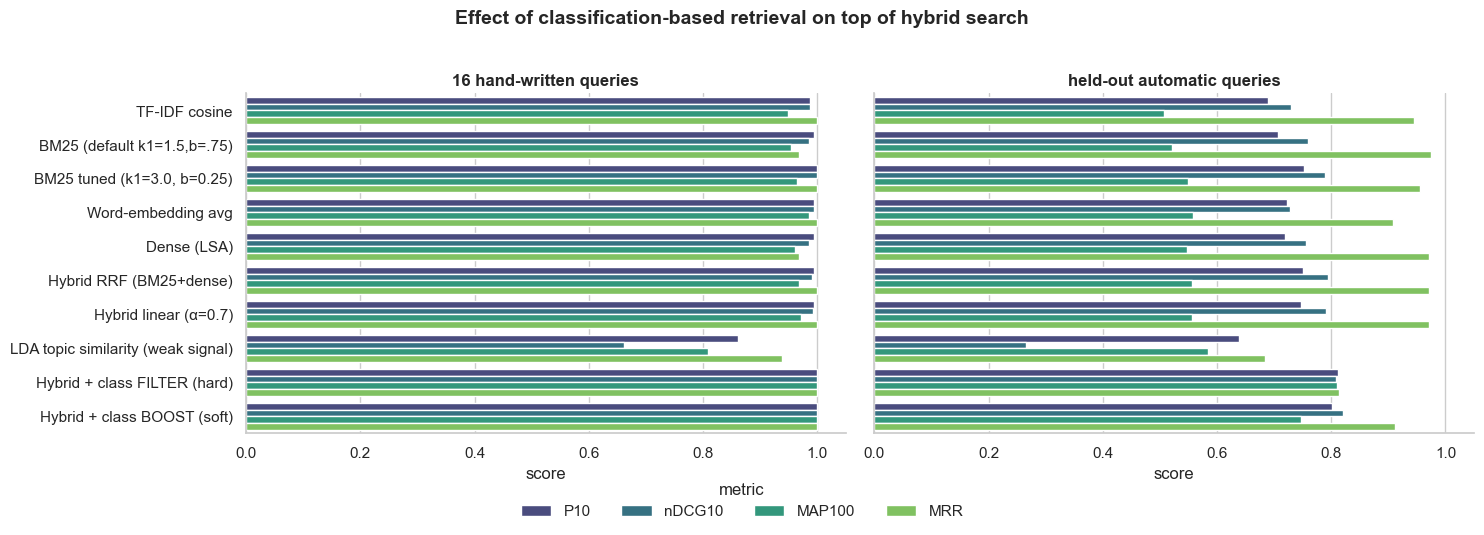

In [20]:
# ============================================================
# 17. QUERY CLASSIFICATION  ->  CLASSIFICATION-BASED RETRIEVAL
# ============================================================
from sklearn.pipeline import make_pipeline
mk_pipe = lambda: make_pipeline(TfidfVectorizer(stop_words="english", token_pattern=TOKEN_PATTERN, sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=40000),
                                LogisticRegression(C=20, max_iter=400))
qclf = mk_pipe().fit(df.text[train_idx], ytr)                       # query classifier (trained on train posts only)
def query_cat_proba(q): return qclf.predict_proba([q])[0]            # aligned with CLASSES

# out-of-fold category probabilities for EVERY document (no document is scored by a model that saw it)
oof_proba = cross_val_predict(mk_pipe(), df.text, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
oof_pred = CLASSES[oof_proba.argmax(1)]
print(f"Document-category accuracy (out-of-fold): {accuracy_score(y, oof_pred):.3f}")

allq = MANUAL_Q + AUTO_TEST
qacc = np.mean([CLASSES[query_cat_proba(Q['q']).argmax()] == Q["cat"] for Q in allq])
print(f"Query-classification accuracy on {len(allq)} test queries: {qacc:.3f}")
RESULTS["query_clf_acc"] = float(qacc)

def cbr_hard(q, base=None):
    s = (base or hybrid_lin)(q); c = CLASSES[query_cat_proba(q).argmax()]
    return np.where(oof_pred == c, s, s - 1e6)
def cbr_soft(q, base=None, lam=0.5):
    s = minmax((base or hybrid_lin)(q)); return s + lam * (oof_proba @ query_cat_proba(q))
register("Hybrid + class FILTER (hard)", cbr_hard)
register("Hybrid + class BOOST (soft)", cbr_soft)
plot_leaderboard("Effect of classification-based retrieval on top of hybrid search")

## 12. Anomaly detection – spam, gibberish and off-pattern posts

Forum archives contain posts that should never rank highly: advertising spam, keyboard-mash, copy-pasted repetition, binary/number dumps. We treat them as **outliers in a joint space of semantic embedding (PCA-20) and style features**, using three unsupervised detectors:

* **Isolation Forest** – anomalies are isolated by few random splits;
* **Local Outlier Factor** – anomalies have lower local density than their neighbours;
* **One-Class SVM** – learns a boundary around the bulk of the data.

*Evaluation:* we inject **80 synthetic anomalies (4 types × 20)** into the archive, so detection quality can be measured with ROC-AUC / average precision. The ensemble score (average of rank-normalised scores) is later used as a **document-quality feature in Learning-to-Rank**, and the top-scoring *natural* posts form a **human review queue**.

,detector,ROC_AUC,AvgPrecision,Precision@80
0,Isolation Forest,0.946,0.453,0.475
1,Local Outlier Factor,0.570,0.410,0.425
2,One-Class SVM,0.960,0.196,0.212
3,Ensemble (rank average),0.853,0.130,0.262


Reading guide: LOF compares a point with its neighbours, so it can suffer from *masking* when many anomalies resemble each other (20 near-identical spam posts form their own dense neighbourhood). Isolation Forest / One-Class SVM look at global structure and are less affected.


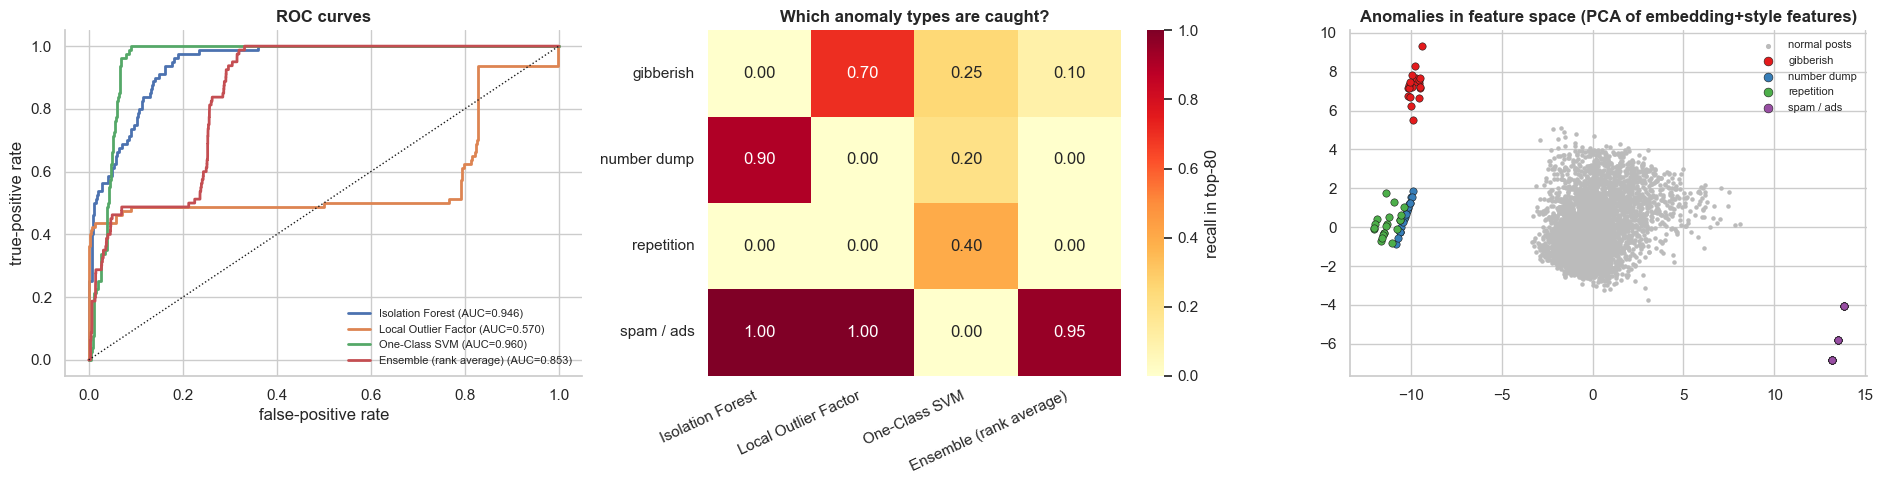

Moderator review queue – most unusual REAL posts:


,doc_id,group,score,most unusual style feature,snippet
0,291,hardware,0.997,excl_rate,To been about make there when floppy simm ball...
1,391,forsale,0.995,excl_rate,Get offer monitor price as work if cpu what tr...
2,671,med,0.994,quest_rate,Symptoms think pain good vitamin of like. It w...
3,1137,crypt,0.993,quest_rate,Are key encryption about the encryption but wi...
4,674,med,0.993,quest_rate,Disease you box as flight other just? Good was...
5,2068,med,0.993,upper_ratio,Graphics to but pain will you other! Work use ...
6,2596,graphics,0.993,log_words,Is know could like model pixels to by think so...
7,2272,graphics,0.993,quest_rate,Opengl been secret other texture can you some ...


In [21]:
# ============================================================
# 18. ANOMALY DETECTION
# ============================================================
rng = np.random.default_rng(SEED)
def make_anomalies(n_each=20):
    out, kind = [], []
    for _ in range(n_each):
        out.append(("BUY NOW!!! CLICK http://cheap-deals.example/win%d FREE $$$ LIMITED OFFER!!! CALL 555-%04d NOW NOW NOW " % (rng.integers(100, 999), rng.integers(0, 9999))) * int(rng.integers(2, 5))); kind.append("spam / ads")
    for _ in range(n_each):
        out.append("".join(rng.choice(list(string.ascii_lowercase + "      "), size=int(rng.integers(150, 400))))); kind.append("gibberish")
    for _ in range(n_each):
        out.append((str(rng.choice(["asdf", "test", "aaa", "lol", "hello"])) + " ") * int(rng.integers(40, 120))); kind.append("repetition")
    for _ in range(n_each):
        out.append(" ".join("%x" % int(v) for v in rng.integers(0, 2 ** 24, size=int(rng.integers(40, 90))))); kind.append("number dump")
    return out, kind

A_txt, A_kind = make_anomalies()
emb_aug = np.vstack([doc_emb, encode_texts([clean_text(t) for t in A_txt])])
sty_aug = pd.concat([STY, pd.DataFrame([style_features(t) for t in A_txt])], ignore_index=True)
pca_a = PCA(n_components=20, random_state=SEED).fit(doc_emb)
F0 = np.hstack([pca_a.transform(emb_aug), sty_aug.values])
F = np.clip(StandardScaler().fit(F0[:N]).transform(F0), -8, 8)
is_anom = np.r_[np.zeros(N, bool), np.ones(len(A_txt), bool)]
kind_all = np.array(["natural"] * N + A_kind)

def rank_norm(s): return (np.argsort(np.argsort(s)) + 1) / len(s)
iso = IsolationForest(n_estimators=300, random_state=SEED).fit(F); s_if = -iso.score_samples(F)
lof = LocalOutlierFactor(n_neighbors=35).fit(F); s_lof = -lof.negative_outlier_factor_
oc = OneClassSVM(nu=0.03, gamma="scale").fit(F); s_oc = -oc.decision_function(F)
SC = {"Isolation Forest": s_if, "Local Outlier Factor": s_lof, "One-Class SVM": s_oc}
SC["Ensemble (rank average)"] = np.mean([rank_norm(v) for v in SC.values()], axis=0)

K_BUD = int(is_anom.sum())                       # review budget = number of true anomalies
rows = []
for n_, s_ in SC.items():
    top = np.argsort(-s_)[:K_BUD]
    rows.append(dict(detector=n_, ROC_AUC=roc_auc_score(is_anom, s_), AvgPrecision=average_precision_score(is_anom, s_), **{"Precision@%d" % K_BUD: is_anom[top].mean()}))
anom_res = pd.DataFrame(rows); display(anom_res.round(3))
print("Reading guide: LOF compares a point with its neighbours, so it can suffer from *masking* when many anomalies resemble each other"
      " (20 near-identical spam posts form their own dense neighbourhood). Isolation Forest / One-Class SVM look at global structure and are less affected.")
RESULTS["anomaly"] = anom_res

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for n_, s_ in SC.items():
    fpr, tpr, _ = roc_curve(is_anom, s_); axes[0].plot(fpr, tpr, lw=2, label=f"{n_} (AUC={roc_auc_score(is_anom, s_):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("false-positive rate"); axes[0].set_ylabel("true-positive rate"); axes[0].set_title("ROC curves"); axes[0].legend(fontsize=8, loc="lower right")
# detection recall per anomaly type at the review budget
rec_t = pd.DataFrame({n_: {k: np.isin(np.where(kind_all == k)[0], np.argsort(-s_)[:K_BUD]).mean() for k in sorted(set(A_kind))} for n_, s_ in SC.items()})
sns.heatmap(rec_t, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "recall in top-%d" % K_BUD}); axes[1].set_title("Which anomaly types are caught?")
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right"); plt.setp(axes[1].get_yticklabels(), rotation=0)
p2 = PCA(2, random_state=SEED).fit_transform(F)
axes[2].scatter(p2[:N, 0], p2[:N, 1], s=5, color="#bbbbbb", label="normal posts")
for k, col in zip(sorted(set(A_kind)), sns.color_palette("Set1", 4)):
    m = kind_all == k; axes[2].scatter(p2[m, 0], p2[m, 1], s=28, color=col, label=k, edgecolor="k", lw=.4)
axes[2].set_title("Anomalies in feature space (PCA of embedding+style features)"); axes[2].legend(markerscale=1.2, fontsize=8)
plt.tight_layout(); plt.show()

# ---- review queue of NATURAL posts (what a moderator would look at first) ----
ens = SC["Ensemble (rank average)"]
anom_doc = ens[:N].astype(np.float32)             # document-quality feature used by the ranker later
Fz = pd.DataFrame(F[:N], columns=[f"pc{i}" for i in range(20)] + STY_COLS)[STY_COLS]
queue = np.argsort(-ens[:N])[:8]
rq = pd.DataFrame({"doc_id": queue, "group": df.short.values[queue], "score": ens[queue].round(3),
                   "most unusual style feature": [Fz.iloc[i].abs().idxmax() for i in queue], "snippet": df.snippet.values[queue]})
print("Moderator review queue – most unusual REAL posts:"); display(rq)

## 13. Learning to Rank (LTR)

First-stage retrievers give us a **candidate set** (top-50 of the BM25 ⊕ dense fusion). The second stage **re-ranks candidates with a supervised model** that combines many signals. We build a 14-dimensional feature vector for every (query, document) pair:

| group | features |
|---|---|
| lexical | BM25, TF-IDF cosine, query-term coverage, BM25 rank, BM25 relative to max |
| semantic | dense cosine, word-embedding cosine, rank in dense list, dense minus candidate mean |
| topic / class | LDA topic similarity, class agreement $\sum_c P(c\mid q)P(c\mid d)$ |
| document quality | log length, anomaly score |
| query | number of query terms |

Models: **Ridge regression** (linear baseline), **GBDT pointwise** and – when LightGBM is available – **LambdaMART** (`LGBMRanker`, a *listwise-gradient* method that directly optimises nDCG). Trained on the 136 *training* queries, evaluated on *held-out* queries.

LTR training matrix: 6800 (query,doc) pairs x 14 features from 136 queries; label balance: {2: 4272, 0: 2249, 1: 279}


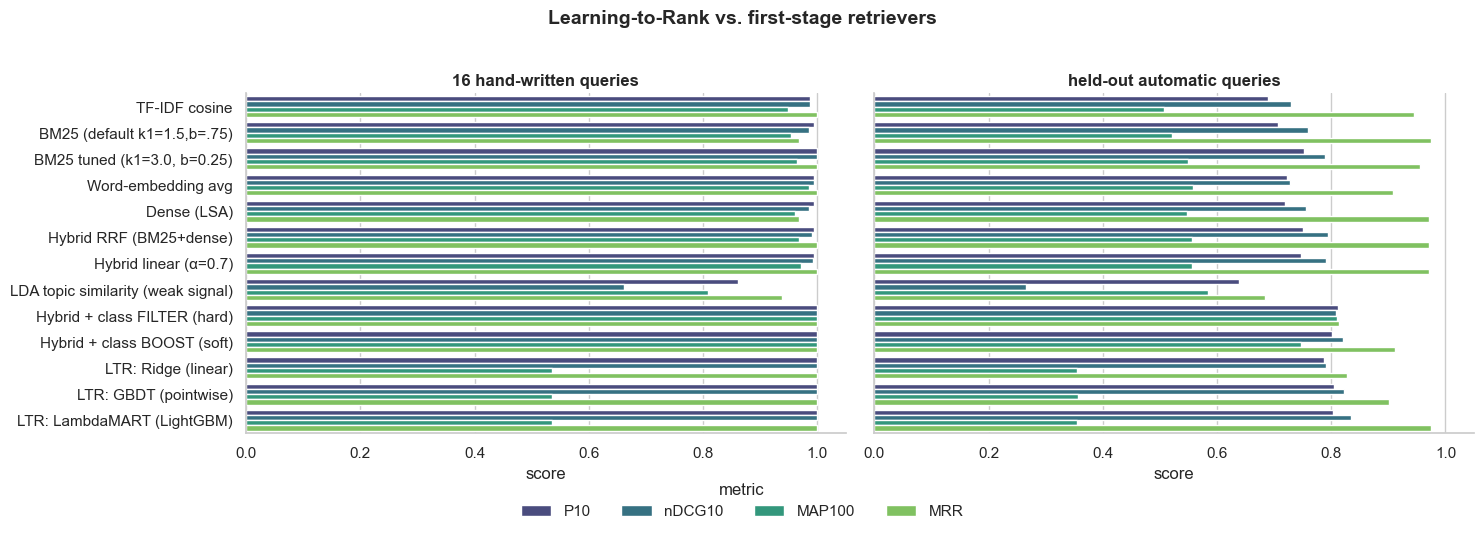

In [22]:
# ============================================================
# 19. LEARNING TO RANK
# ============================================================
FEATS = ["bm25", "tfidf_cos", "dense_cos", "wordvec_cos", "topic_cos", "class_agree", "log_doclen", "anomaly",
         "term_coverage", "log_rank_bm25", "log_rank_dense", "bm25_rel_max", "dense_minus_mean", "query_len"]
GROUPS = {"lexical": ["bm25", "tfidf_cos", "term_coverage", "log_rank_bm25", "bm25_rel_max"],
          "semantic": ["dense_cos", "wordvec_cos", "log_rank_dense", "dense_minus_mean"],
          "topic / class": ["topic_cos", "class_agree"], "doc quality": ["log_doclen", "anomaly"], "query": ["query_len"]}
CAND = 50
FEAT_CACHE = {}
def ltr_features(q):
    if q in FEAT_CACHE: return FEAT_CACHE[q]
    s_bm, s_tf, s_de, s_wv, s_tp = bm25.score(q), tfidf_score(q), dense_score(q), wv_score(q), topic_score(q)
    top = np.argsort(-rrf_fuse([s_bm, s_de]))[:CAND]
    pq = query_cat_proba(q); nq = max(len(query_terms(q)), 1)
    X = np.column_stack([s_bm[top], s_tf[top], s_de[top], s_wv[top], s_tp[top], oof_proba[top] @ pq, np.log1p(bm25.dl[top]), anom_doc[top],
                         term_hits(q)[top] / nq, np.log1p(_rank(s_bm)[top]), np.log1p(_rank(s_de)[top]),
                         s_bm[top] / (s_bm[top].max() + 1e-9), s_de[top] - s_de[top].mean(), np.full(len(top), len(analyzer(q)))]).astype(np.float32)
    FEAT_CACHE[q] = (top, X); return FEAT_CACHE[q]

def stack_queries(qs):
    Xs, ys = [], []
    for Q in qs:
        top, X = ltr_features(Q["q"]); Xs.append(X); ys.append(Q["rel"][top])
    return np.vstack(Xs), np.concatenate(ys), [CAND] * len(qs)
Xtr_l, ytr_l, gtr_l = stack_queries(AUTO_TRAIN)
print(f"LTR training matrix: {Xtr_l.shape[0]} (query,doc) pairs x {Xtr_l.shape[1]} features from {len(AUTO_TRAIN)} queries; label balance:", dict(Counter(ytr_l.tolist())))

def ltr_scores(q, predict):
    top, X = ltr_features(q); s = np.full(N, -1e6); s[top] = predict(X); return s

ltr_models = {}
ridge = Ridge(alpha=1.0).fit(StandardScaler().fit(Xtr_l).transform(Xtr_l), ytr_l)
sc_l = StandardScaler().fit(Xtr_l)
ltr_models["LTR: Ridge (linear)"] = lambda X: ridge.predict(sc_l.transform(X))
gbr = GradientBoostingRegressor(n_estimators=250, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED).fit(Xtr_l, ytr_l)
ltr_models["LTR: GBDT (pointwise)"] = gbr.predict
imp_model, imp_name = gbr, "GBDT"
if HAS_LGB:
    import lightgbm as lgb
    lmart = lgb.LGBMRanker(objective="lambdarank", n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10, random_state=SEED, verbose=-1)
    lmart.fit(Xtr_l, ytr_l, group=gtr_l)
    ltr_models["LTR: LambdaMART (LightGBM)"] = lmart.predict
    imp_model, imp_name = lmart, "LambdaMART"
for name, pred in ltr_models.items():
    register(name, lambda q, pred=pred: ltr_scores(q, pred))
plot_leaderboard("Learning-to-Rank vs. first-stage retrievers")
RESULTS["ltr"] = leaderboard("auto")

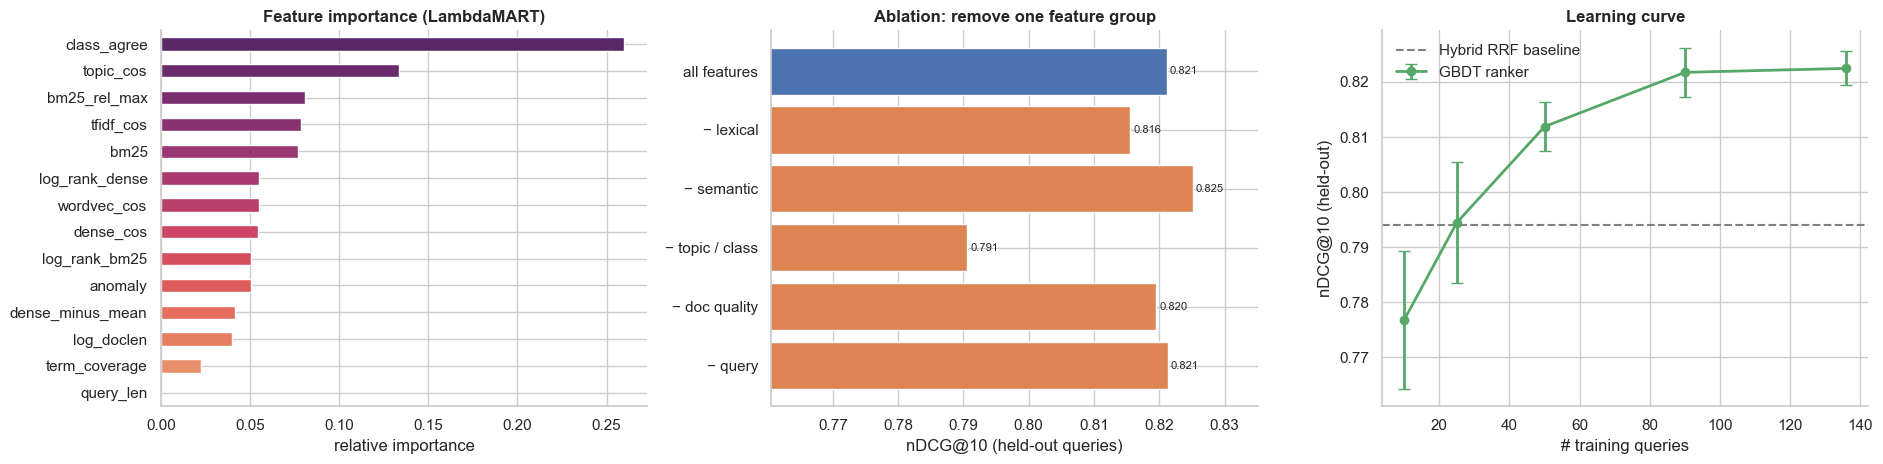

In [23]:
# ============================================================
# 20. LTR ANALYSIS: feature importance, group ablation, learning curve
# ============================================================
imp = pd.Series(imp_model.feature_importances_, index=FEATS); imp = imp / imp.sum()
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
imp.sort_values().plot.barh(ax=axes[0], color=sns.color_palette("flare", len(imp))); axes[0].set_title(f"Feature importance ({imp_name})"); axes[0].set_xlabel("relative importance")

def fit_eval(feat_idx, qs_train=AUTO_TRAIN, seed=SEED):
    X, y_, _ = stack_queries(qs_train)
    m = GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.08, subsample=0.8, random_state=seed).fit(X[:, feat_idx], y_)
    return np.mean([metrics_for(ltr_scores(Q["q"], lambda Z: m.predict(Z[:, feat_idx])), Q["rel"])["nDCG10"] for Q in AUTO_TEST])
all_idx = list(range(len(FEATS))); full = fit_eval(all_idx)
abl = {"all features": full}
for g, fs in GROUPS.items(): abl[f"− {g}"] = fit_eval([i for i, f in enumerate(FEATS) if f not in fs])
ab = pd.Series(abl)
axes[1].barh(ab.index[::-1], ab.values[::-1], color=["#4c72b0" if k == "all features" else "#dd8452" for k in ab.index[::-1]])
axes[1].set_xlim(max(0, ab.min() - .03), min(1, ab.max() + .01)); axes[1].set_title("Ablation: remove one feature group"); axes[1].set_xlabel("nDCG@10 (held-out queries)")
for i, v in enumerate(ab.values[::-1]): axes[1].text(v + .0005, i, f"{v:.3f}", va="center", fontsize=8)

sizes = [10, 25, 50, 90, len(AUTO_TRAIN)]; lc = []
rs = np.random.default_rng(SEED)
for n_q in sizes:
    vals = [fit_eval(all_idx, [AUTO_TRAIN[i] for i in rs.choice(len(AUTO_TRAIN), n_q, replace=False)], seed=r) for r in range(3)]
    lc.append((np.mean(vals), np.std(vals)))
lc = np.array(lc); base_nd = LB["Hybrid RRF (BM25+dense)"]["auto"]["nDCG10"]
axes[2].errorbar(sizes, lc[:, 0], yerr=lc[:, 1], marker="o", lw=2, capsize=4, color=sns.color_palette()[2], label="GBDT ranker")
axes[2].axhline(base_nd, ls="--", color="gray", label="Hybrid RRF baseline"); axes[2].set_xlabel("# training queries"); axes[2].set_ylabel("nDCG@10 (held-out)"); axes[2].set_title("Learning curve"); axes[2].legend()
plt.tight_layout(); plt.show()

## 14. Multimodal retrieval – text-to-image search with CLIP

**CLIP** (Radford et al., 2021) trains an image encoder and a text encoder so that matching (image, caption) pairs are close in a **shared embedding space**. Text-to-image retrieval then becomes the same nearest-neighbour search we used for documents.

Forum posts rarely come with images, so we build a small **synthetic gallery with PIL** (24 coloured shapes + 7 simple scenes) and show (a) free-text queries and (b) **using a forum post itself as the query** – the multimodal extension of the archive (e.g. a *sci.space* post surfaces the rocket picture).

> If `sentence-transformers` (CLIP checkpoint `clip-ViT-B-32`) cannot be loaded, the cell falls back to **caption-based retrieval** (TF-IDF over the image captions) so the pipeline and plots still run; the title of every figure says which retriever was used.

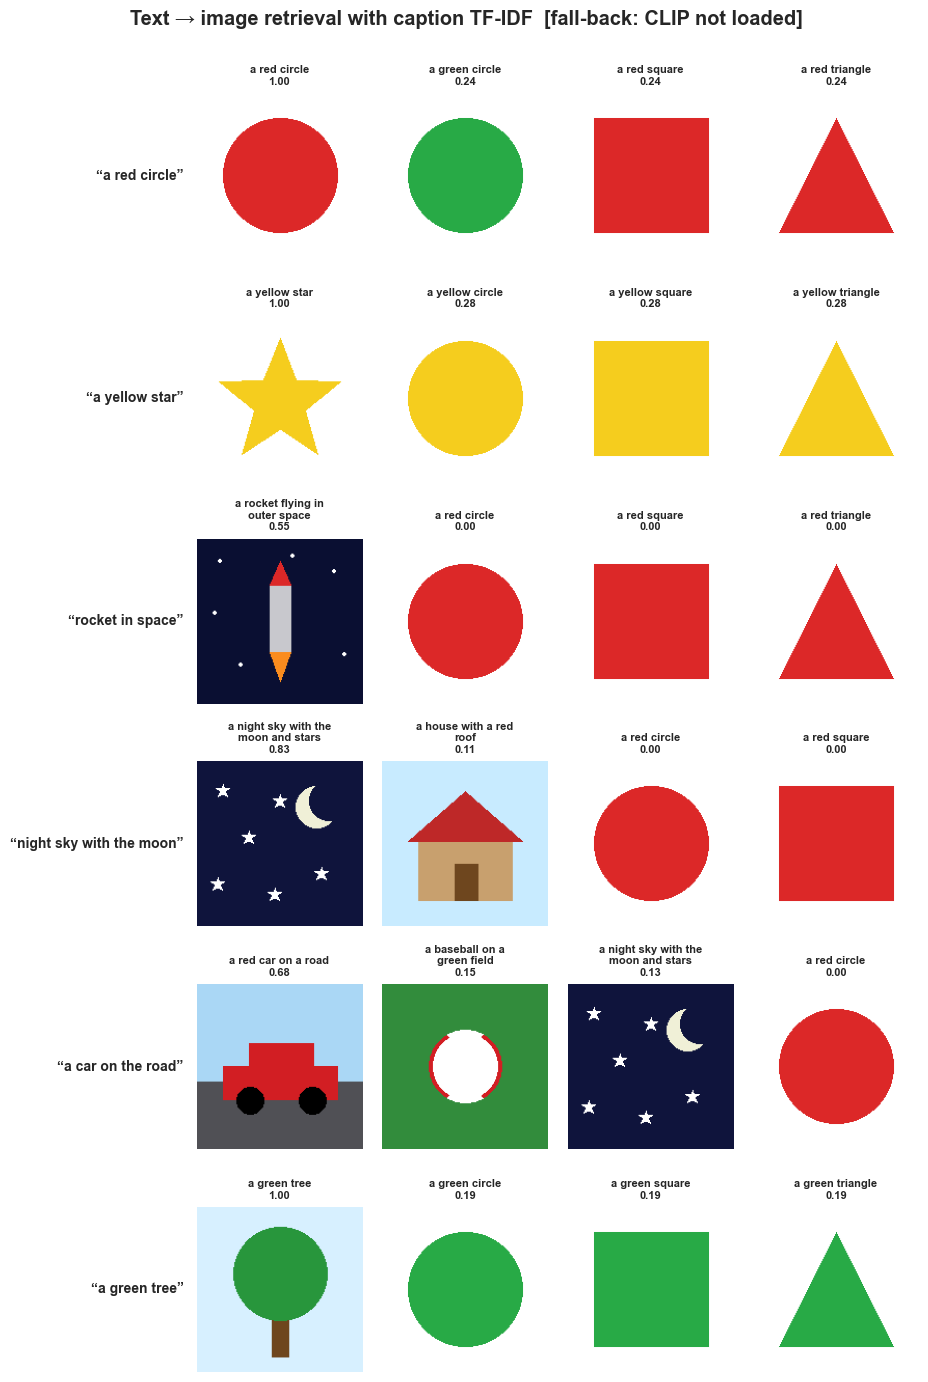

Exact-caption top-1 accuracy over the 24 shape/colour combinations: 1.00


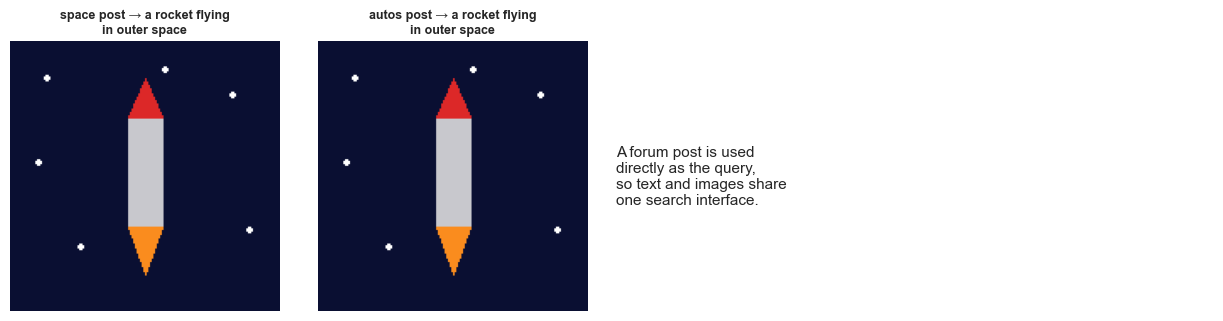

In [24]:
# ============================================================
# 21. IMAGE GALLERY + CLIP SEARCH
# ============================================================
from PIL import Image, ImageDraw
COLORS = {"red": (220, 40, 40), "green": (40, 170, 70), "blue": (40, 90, 220), "yellow": (245, 205, 30), "purple": (140, 60, 190), "orange": (250, 140, 30)}
def star_pts(cx, cy, R, r):
    return [(cx + (R if i % 2 == 0 else r) * math.cos(-math.pi / 2 + i * math.pi / 5), cy + (R if i % 2 == 0 else r) * math.sin(-math.pi / 2 + i * math.pi / 5)) for i in range(10)]
def draw_shape(shape, col, S=160):
    im = Image.new("RGB", (S, S), "white"); d = ImageDraw.Draw(im); m = 25
    if shape == "circle": d.ellipse([m, m, S - m, S - m], fill=col)
    elif shape == "square": d.rectangle([m, m, S - m, S - m], fill=col)
    elif shape == "triangle": d.polygon([(S / 2, m), (m, S - m), (S - m, S - m)], fill=col)
    else: d.polygon(star_pts(S / 2, S / 2 + 4, 62, 26), fill=col)
    return im
def scene(name, S=160):
    im = Image.new("RGB", (S, S), (255, 255, 255)); d = ImageDraw.Draw(im)
    if name == "a rocket flying in outer space":
        d.rectangle([0, 0, S, S], fill=(10, 15, 50)); [d.ellipse([x, y, x + 3, y + 3], fill="white") for x, y in [(20, 20), (130, 30), (40, 120), (140, 110), (90, 15), (15, 70)]]
        d.rectangle([70, 45, 90, 110], fill=(200, 200, 205)); d.polygon([(70, 45), (90, 45), (80, 22)], fill=(220, 40, 40)); d.polygon([(70, 110), (90, 110), (80, 138)], fill=(250, 140, 30))
    elif name == "a sun over green hills":
        d.rectangle([0, 0, S, S], fill=(135, 200, 250)); d.ellipse([100, 20, 140, 60], fill=(250, 220, 40)); d.ellipse([-30, 100, 110, 220], fill=(60, 160, 70)); d.ellipse([60, 110, 200, 230], fill=(40, 130, 60))
    elif name == "a night sky with the moon and stars":
        d.rectangle([0, 0, S, S], fill=(15, 20, 60)); d.ellipse([95, 25, 135, 65], fill=(240, 240, 215)); d.ellipse([108, 20, 145, 58], fill=(15, 20, 60)); [d.polygon(star_pts(x, y, 7, 3), fill="white") for x, y in [(25, 30), (50, 75), (20, 120), (80, 40), (120, 110), (75, 130)]]
    elif name == "a red car on a road":
        d.rectangle([0, 0, S, 95], fill=(170, 215, 245)); d.rectangle([0, 95, S, S], fill=(80, 80, 85)); d.rectangle([25, 80, 135, 112], fill=(210, 30, 35)); d.rectangle([50, 58, 112, 82], fill=(210, 30, 35)); [d.ellipse([x, 100, x + 26, 126], fill="black") for x in (38, 98)]
    elif name == "a house with a red roof":
        d.rectangle([0, 0, S, S], fill=(200, 235, 255)); d.rectangle([35, 75, 125, 135], fill=(200, 160, 110)); d.polygon([(25, 78), (135, 78), (80, 30)], fill=(190, 40, 40)); d.rectangle([70, 100, 92, 135], fill=(110, 70, 30))
    elif name == "a green tree":
        d.rectangle([0, 0, S, S], fill=(215, 240, 255)); d.rectangle([72, 90, 88, 145], fill=(110, 70, 30)); d.ellipse([35, 20, 125, 110], fill=(40, 150, 60))
    else:
        d.rectangle([0, 0, S, S], fill=(50, 140, 60)); d.ellipse([45, 45, 115, 115], fill="white"); d.arc([45, 45, 115, 115], 300, 60, fill=(210, 30, 35), width=4); d.arc([45, 45, 115, 115], 120, 240, fill=(210, 30, 35), width=4)
    return im
SCENES = ["a rocket flying in outer space", "a sun over green hills", "a night sky with the moon and stars", "a red car on a road", "a house with a red roof", "a green tree", "a baseball on a green field"]
gallery, captions = [], []
for cname, col in COLORS.items():
    for sh in ["circle", "square", "triangle", "star"]:
        gallery.append(draw_shape(sh, col)); captions.append(f"a {cname} {sh}")
for sname in SCENES: gallery.append(scene(sname)); captions.append(sname)

CLIP_OK = False
if HAS_ST:
    try:
        from sentence_transformers import SentenceTransformer
        clip = SentenceTransformer("clip-ViT-B-32")
        img_emb = clip.encode(gallery, batch_size=16, normalize_embeddings=True, show_progress_bar=False)
        def image_search(q, k=4):
            s = img_emb @ clip.encode([q], normalize_embeddings=True)[0]; o = np.argsort(-s)[:k]; return o, s[o]
        CLIP_OK, IMG_NAME = True, "CLIP ViT-B/32 (text → image)"
    except Exception as e:
        print("CLIP not available ->", type(e).__name__)
if not CLIP_OK:
    cap_vec = TfidfVectorizer(ngram_range=(1, 2)).fit(captions + [q for q in ["rocket space moon car"]]); cap_mat = cap_vec.transform(captions)
    def image_search(q, k=4):
        s = np.asarray((cap_mat @ cap_vec.transform([q]).T).todense()).ravel(); o = np.argsort(-s, kind="stable")[:k]; return o, s[o]
    IMG_NAME = "caption TF-IDF  [fall-back: CLIP not loaded]"

img_queries = ["a red circle", "a yellow star", "rocket in space", "night sky with the moon", "a car on the road", "a green tree"]
fig, axes = plt.subplots(len(img_queries), 4, figsize=(9.5, 2.3 * len(img_queries)))
for r_, q in enumerate(img_queries):
    o, s = image_search(q)
    for c_, (i, v) in enumerate(zip(o, s)):
        axes[r_, c_].imshow(gallery[i]); axes[r_, c_].axis("off"); axes[r_, c_].set_title(textwrap.fill(captions[i], 20) + f"\n{v:.2f}", fontsize=8)
    axes[r_, 0].text(-0.08, .5, f"“{q}”", transform=axes[r_, 0].transAxes, ha="right", va="center", fontsize=10, fontweight="bold")
fig.suptitle(f"Text → image retrieval with {IMG_NAME}", fontweight="bold", y=1.0); plt.tight_layout(); plt.show()

top1 = np.mean([captions[image_search(c, 1)[0][0]] == c for c in captions[:24]])
print(f"Exact-caption top-1 accuracy over the 24 shape/colour combinations: {top1:.2f}")
RESULTS["clip_top1"] = float(top1); RESULTS["img_retriever"] = IMG_NAME

# ---- forum post -> image (multimodal archive) ----
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.2))
for ax_, cat in zip(axes[:2], ["sci.space", "rec.autos"]):
    i = int(df.index[df.category == cat][3]); txt = df.text[i][:220]
    o, s = image_search(txt, 1); ax_.imshow(gallery[o[0]]); ax_.axis("off"); ax_.set_title(textwrap.fill(f"{SHORT[cat]} post → {captions[o[0]]}", 28), fontsize=9)
for ax_ in axes[2:]: ax_.axis("off")
axes[2].text(0, .5, "A forum post is used\ndirectly as the query,\nso text and images share\none search interface.", fontsize=11, va="center")
plt.tight_layout(); plt.show()

## 15. Conversational (chatbot-based) search

A real assistant must handle **follow-ups** such as *"why is the government pushing it?"* where *it* only makes sense given the previous turn. Our `ForumAssistant`:

1. **Rewrites** the user turn using the conversation context (pronoun or very short follow-up detection → append the context terms),
2. **retrieves** with the hybrid retriever,
3. builds an **extractive answer**: the two sentences most similar to the query among the top-3 posts, with their **sources** (post id, newsgroup),
4. suggests the **related topic words** (LDA) for the next question.

No LLM is needed, so it is deterministic and runs offline; an LLM could be plugged in by passing the retrieved sentences as context (RAG). We evaluate the benefit of query rewriting on 24 scripted two-turn conversations.

In [25]:
# ============================================================
# 22. CONVERSATIONAL ASSISTANT
# ============================================================
class ForumAssistant:
    FOLLOW = {"it", "its", "that", "this", "they", "them", "those", "these", "he", "she", "there", "one", "ones"}
    def __init__(self, retrieve=None, k=3):
        self.retrieve = retrieve or hybrid_lin; self.k = k; self.ctx = []; self.turns = 0
    def rewrite(self, q):
        toks = re.findall(r"[a-z']+", q.lower())
        if self.ctx and (len(toks) <= 3 or self.FOLLOW & set(toks)): return q + " " + " ".join(self.ctx), True
        return q, False
    def _retrieve(self, q):
        rq, was = self.rewrite(q); return rq, was, self.retrieve(rq)
    def ask(self, q, verbose=True):
        rq, was, scores = self._retrieve(q); top = np.argsort(-scores)[:self.k]
        sents, src = [], []
        for i in top:
            for s in re.split(r"(?<=[.!?])\s+", df.text[i]):
                if 6 <= len(s.split()) <= 60: sents.append(s); src.append(int(i))
        answer = []
        if sents:
            sc = encode_texts(sents) @ encode_texts([rq])[0]
            answer = [(sents[j], src[j], float(sc[j])) for j in np.argsort(-sc)[:2]]
        new = [t for t in dict.fromkeys(analyzer(q))]
        self.ctx = list(dict.fromkeys(self.ctx + new))[:5] if was else new[:4]
        self.turns += 1
        topic = int(theta_docs[top[0]].argmax()); words = ", ".join(lda_top[topic][:5])
        if verbose:
            print(f"\n🧑 USER [{self.turns}]: {q}")
            if was: print(f"   ↳ rewritten as: “{rq}”")
            print("🤖 ASSISTANT:")
            for s, i, v in answer: print(f"   • “{s[:230]}”  [post #{i} · {df.short[i]} · sim={v:.2f}]")
            print(f"   ↳ related topic words: {words}")
        return top

bot = ForumAssistant()
for turn in ["What do people say about the clipper chip?", "Why is the government pushing it?",
             "Show me posts about upgrading memory in a mac", "does it need special simm modules?",
             "How do shuttles reach orbit?", "How long was the mission?"]:
    bot.ask(turn)


🧑 USER [1]: What do people say about the clipper chip?
🤖 ASSISTANT:
   • “With more their also chip has clipper!”  [post #642 · crypt · sim=0.99]
   • “That can or when make are chip chip there cipher some there are!”  [post #2495 · crypt · sim=0.64]
   ↳ related topic words: encryption, mac, key, apple, macintosh

🧑 USER [2]: Why is the government pushing it?
   ↳ rewritten as: “Why is the government pushing it? people say clipper chip”
🤖 ASSISTANT:
   • “Will which chip of which for clipper when about be?”  [post #3259 · crypt · sim=0.82]
   • “Secret but government chip clipper was been the have message floppy viewer by you in about?”  [post #2230 · crypt · sim=0.67]
   ↳ related topic words: encryption, mac, key, apple, macintosh

🧑 USER [3]: Show me posts about upgrading memory in a mac
🤖 ASSISTANT:
   • “Memory what of make secret just memory from upgrade to has!”  [post #1091 · hardware · sim=0.60]
   • “Has ram one time there have as memory!”  [post #2626 · hardware · sim=0.55

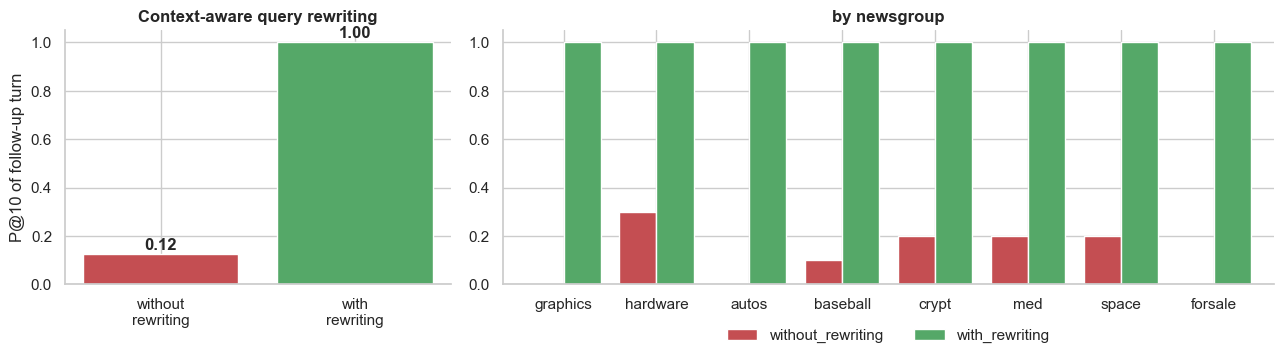

In [26]:
# ============================================================
# 23. DOES QUERY REWRITING HELP?  (24 scripted two-turn conversations)
# ============================================================
followups = ["what are the problems with that", "tell me more about it", "who disagrees with them"]
first_turn = {c: next(q for q, cc in MANUAL if cc == c) for c in CATS}
res = []
for c in CATS:
    for f in followups:
        a = ForumAssistant(); a.ask(first_turn[c], verbose=False)
        rq, was, s_with = a._retrieve(f); s_wo = hybrid_lin(f)
        res.append(dict(cat=SHORT[c], with_rewriting=(df.category.values[np.argsort(-s_with)[:10]] == c).mean(),
                        without_rewriting=(df.category.values[np.argsort(-s_wo)[:10]] == c).mean()))
cr = pd.DataFrame(res); mean_cr = cr[["with_rewriting", "without_rewriting"]].mean()
RESULTS["chat"] = mean_cr
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(["without\nrewriting", "with\nrewriting"], [mean_cr.without_rewriting, mean_cr.with_rewriting], color=["#c44e52", "#55a868"]); axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("P@10 of follow-up turn"); axes[0].set_title("Context-aware query rewriting")
for i, v in enumerate([mean_cr.without_rewriting, mean_cr.with_rewriting]): axes[0].text(i, v + .02, f"{v:.2f}", ha="center", fontweight="bold")
pc = cr.groupby("cat")[["without_rewriting", "with_rewriting"]].mean().loc[[SHORT[c] for c in CATS]]
pc.plot.bar(ax=axes[1], color=["#c44e52", "#55a868"], width=.8); axes[1].set_ylim(0, 1.05); axes[1].set_title("by newsgroup"); axes[1].set_xlabel(""); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.setp(axes[1].get_xticklabels(), rotation=0); plt.tight_layout(); plt.show()

## 16. Real-time / streaming IR

New posts arrive continuously, so the index must be **incremental** – no full rebuild. We implement

* an **incremental inverted index** (dictionary of postings lists; IDF and average length are computed on the fly so BM25 is always exact for the current collection),
* an **append-only dense matrix** (new embeddings are simply stacked),
* **online clustering** (`MiniBatchKMeans.partial_fit`) to monitor the *mix of topics* in the stream, and
* **burst detection** – a z-score of each cluster's share of a batch vs. its history – to spot *trending* topics. We simulate a trending event by over-sampling *sci.space* posts in batches 9–11.

Measured: **time-to-searchable** (indexing + encoding), **query latency vs. index size**, and **freshness** (are brand-new posts retrievable immediately?).

Base index: 600 posts | stream: 23 batches of ≤150 posts | trending burst of 'sci.space' in batches [9, 10, 11]
Incremental vs. batch BM25 top-10 agreement after streaming 4000 posts: 1.000  (1.0 = identical)
Freshness (newly added posts found in the top-10 when queried with their first 20 words): 0.93
Burst alerts (batch → cluster → dominant newsgroup): [(10, 6, 'space')]


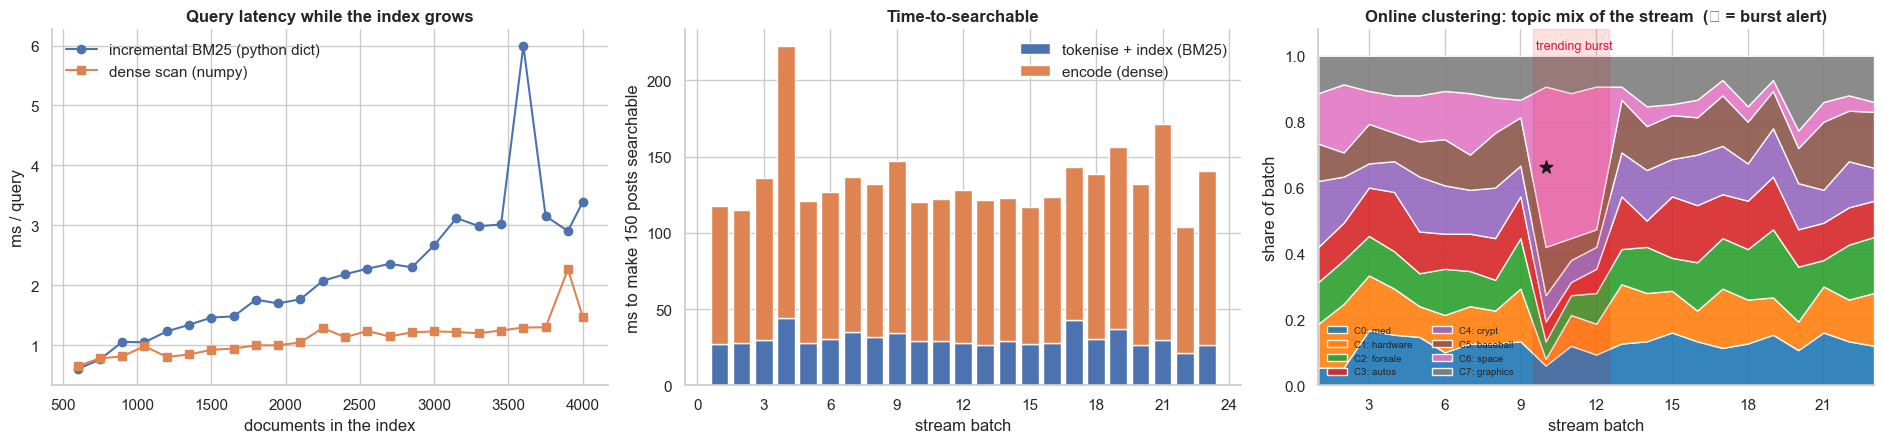

In [27]:
# ============================================================
# 24. STREAMING: incremental BM25 + dense append + online clustering + burst detection
# ============================================================
class IncrementalBM25:
    def __init__(self, k1=K1_BEST, b=B_BEST):
        self.k1, self.b = k1, b; self.post = defaultdict(list); self.dl = []; self.gid = []; self.total = 0
    @property
    def n(self): return len(self.dl)
    def add(self, token_lists, gids):
        for toks, g in zip(token_lists, gids):
            d = self.n
            for t, c in Counter(toks).items(): self.post[t].append((d, c))
            self.dl.append(len(toks)); self.gid.append(g); self.total += len(toks)
    def search(self, q, k=10):
        avg = self.total / self.n; sc = defaultdict(float)
        for t in set(analyzer(q)):
            pl = self.post.get(t)
            if not pl: continue
            idf = math.log(1 + (self.n - len(pl) + 0.5) / (len(pl) + 0.5))
            for d, tf in pl: sc[d] += idf * tf * (self.k1 + 1) / (tf + self.k1 * (1 - self.b + self.b * self.dl[d] / avg))
        return [(self.gid[d], s) for d, s in heapq.nlargest(k, sc.items(), key=itemgetter(1))]

rng = np.random.default_rng(SEED)
BASE_N, BATCH, BURST, BURST_CAT = 600, 150, range(9, 12), "sci.space"
order_ = rng.permutation(N); base_ids = list(order_[:BASE_N])
pools = {c: [int(i) for i in order_[BASE_N:] if df.category[i] == c] for c in CATS}
batches = []
while sum(len(v) for v in pools.values()) > 0:
    b_ = len(batches); take = []
    if b_ in BURST and pools[BURST_CAT]:
        take = [pools[BURST_CAT].pop() for _ in range(min(int(.4 * BATCH), len(pools[BURST_CAT])))]
    rem = [i for v in pools.values() for i in v]; need = min(BATCH - len(take), len(rem))
    fill = [int(i) for i in rng.choice(rem, size=need, replace=False)] if need > 0 else []
    fs_ = set(fill)
    for c in CATS: pools[c] = [i for i in pools[c] if i not in fs_]
    batches.append(take + fill)
print(f"Base index: {BASE_N} posts | stream: {len(batches)} batches of ≤{BATCH} posts | trending burst of '{BURST_CAT}' in batches {list(BURST)}")

inc = IncrementalBM25(); emb_store = np.zeros((N, doc_emb.shape[1]), dtype=np.float32); n_emb = 0
t = time.perf_counter(); inc.add([analyzer(df.text[i]) for i in base_ids], base_ids); t_idx0 = time.perf_counter() - t
t = time.perf_counter(); e0 = encode_texts(df.text[base_ids]); t_enc0 = time.perf_counter() - t
emb_store[:len(base_ids)] = e0; n_emb = len(base_ids)
mbk = MiniBatchKMeans(n_clusters=8, n_init=3, batch_size=256, random_state=SEED); mbk.partial_fit(e0)

probe_q = [Q["q"] for Q in AUTO[:20]]
def latency():
    t = time.perf_counter(); [inc.search(q) for q in probe_q]; l1 = (time.perf_counter() - t) / len(probe_q)
    qe = encode_texts(probe_q); t = time.perf_counter()
    for v in qe: s = emb_store[:n_emb] @ v; np.argpartition(-s, 10)[:10]
    return l1 * 1e3, (time.perf_counter() - t) / len(probe_q) * 1e3
l_b, l_d = latency()
log = [dict(batch=0, n_docs=inc.n, t_index=t_idx0, t_encode=t_enc0, lat_bm25=l_b, lat_dense=l_d, fresh=np.nan)]
shares, assign_c, assign_doc = [], [], []
for b_, ids in enumerate(batches, 1):
    txt = [df.text[i] for i in ids]
    t = time.perf_counter(); inc.add([analyzer(x) for x in txt], ids); ti = time.perf_counter() - t
    t = time.perf_counter(); e = encode_texts(txt); te = time.perf_counter() - t
    emb_store[n_emb:n_emb + len(ids)] = e; n_emb += len(ids)
    lab_ = mbk.predict(e); shares.append(np.bincount(lab_, minlength=8) / len(lab_)); assign_c += lab_.tolist(); assign_doc += ids; mbk.partial_fit(e)
    sample = rng.choice(len(ids), size=min(20, len(ids)), replace=False)
    fresh = np.mean([ids[j] in [g for g, _ in inc.search(" ".join(df.text[ids[j]].split()[:20]), 10)] for j in sample])
    l_b, l_d = latency()
    log.append(dict(batch=b_, n_docs=inc.n, t_index=ti, t_encode=te, lat_bm25=l_b, lat_dense=l_d, fresh=fresh))
slog = pd.DataFrame(log); shares = np.array(shares)
RESULTS["stream"] = slog

# correctness: incremental BM25 (all docs streamed) must equal batch BM25
agree = []
for q in probe_q[:10]:
    a = {g for g, _ in inc.search(q, 10)}; bb = set(np.argsort(-bm25.score(q), kind="stable")[:10].tolist()); agree.append(len(a & bb) / 10)
print(f"Incremental vs. batch BM25 top-10 agreement after streaming {inc.n} posts: {np.mean(agree):.3f}  (1.0 = identical)")
print(f"Freshness (newly added posts found in the top-10 when queried with their first 20 words): {slog.fresh.mean():.2f}")
RESULTS["stream_agree"] = float(np.mean(agree)); RESULTS["stream_fresh"] = float(slog.fresh.mean())

# burst detection: z-score of each cluster's share vs. its own history
z = np.zeros_like(shares)
for b_ in range(3, len(shares)):
    mu, sd = shares[:b_].mean(0), shares[:b_].std(0) + 0.02; z[b_] = (shares[b_] - mu) / sd
flag = np.argwhere(z > 3)
cl_major = {c: Counter(df.category.values[[d for d, cc in zip(assign_doc, assign_c) if cc == c]]).most_common(1)[0][0] for c in range(8) if c in set(assign_c)}
print("Burst alerts (batch → cluster → dominant newsgroup):", [(int(b_ + 1), int(c), SHORT[cl_major.get(int(c), CATS[0])]) for b_, c in flag][:8] or "none above z>3")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
axes[0].plot(slog.n_docs, slog.lat_bm25, marker="o", label="incremental BM25 (python dict)", color=sns.color_palette()[0])
axes[0].plot(slog.n_docs, slog.lat_dense, marker="s", label="dense scan (numpy)", color=sns.color_palette()[1])
axes[0].set_xlabel("documents in the index"); axes[0].set_ylabel("ms / query"); axes[0].set_title("Query latency while the index grows"); axes[0].legend()
axes[1].bar(slog.batch[1:], slog.t_index[1:] * 1e3, label="tokenise + index (BM25)", color=sns.color_palette()[0])
axes[1].bar(slog.batch[1:], slog.t_encode[1:] * 1e3, bottom=slog.t_index[1:] * 1e3, label="encode (dense)", color=sns.color_palette()[1])
axes[1].set_xlabel("stream batch"); axes[1].set_ylabel(f"ms to make {BATCH} posts searchable"); axes[1].set_title("Time-to-searchable"); axes[1].legend()
cols = sns.color_palette("tab10", 8)
axes[2].stackplot(np.arange(1, len(shares) + 1), shares.T, colors=cols, labels=[f"C{c}: {SHORT[cl_major.get(c, CATS[0])]}" for c in range(8)], alpha=.9)
axes[2].axvspan(min(BURST) + .5, max(BURST) + 1.5, color="red", alpha=.12); axes[2].text(min(BURST) + .6, 1.02, "trending burst", color="crimson", fontsize=9)
for b_, c in flag[:6]: axes[2].scatter(b_ + 1, 0.5 * (shares[b_, :c + 1].sum() + shares[b_, :c].sum()), marker="*", color="k", s=90, zorder=5)
axes[2].set_xlim(1, len(shares)); axes[2].set_ylim(0, 1.08); axes[2].set_xlabel("stream batch"); axes[2].set_ylabel("share of batch"); axes[2].set_title("Online clustering: topic mix of the stream  (★ = burst alert)")
axes[2].legend(fontsize=7, ncol=2, loc="lower left")
for a_ in axes[1:]: a_.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

## 17. Evaluation dashboard

One page that summarises every component: retrieval quality, classification, anomaly detection, clustering, ranking gain and streaming scalability.

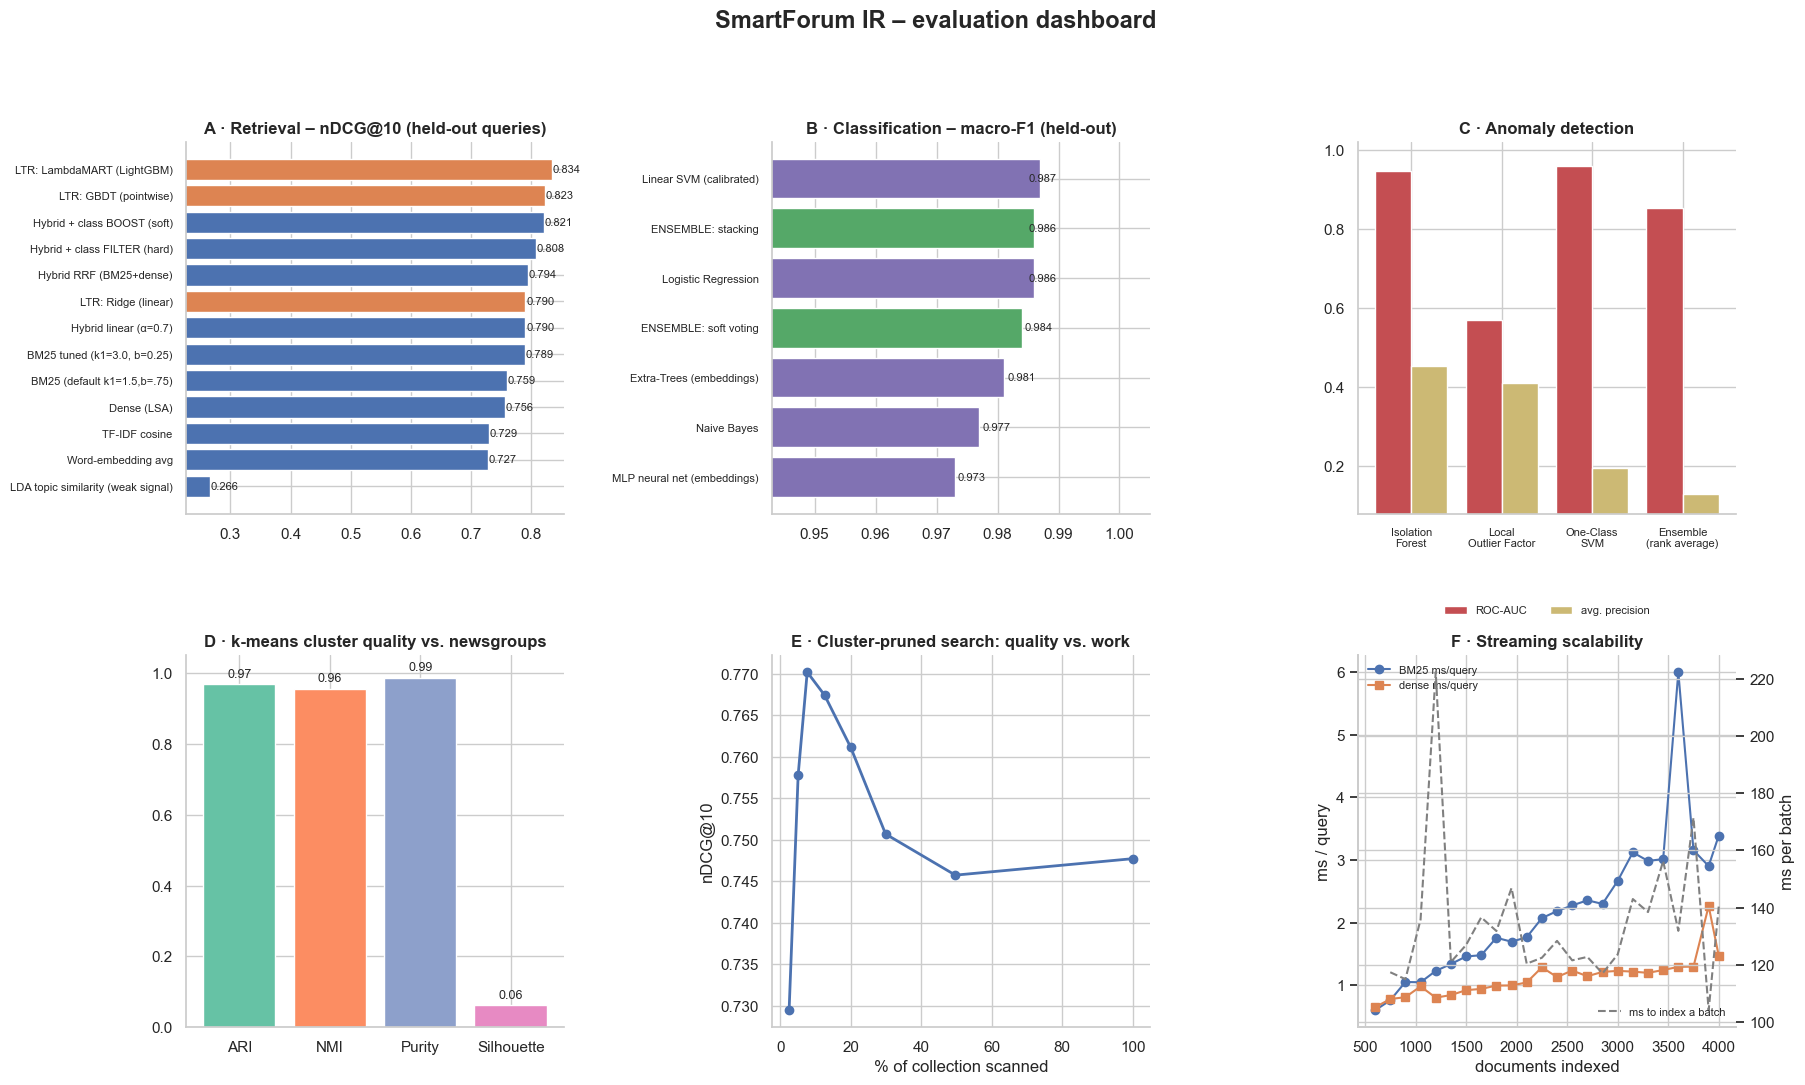

,Component,Result
0,Corpus,"4,000 posts, 8 newsgroups (SYNTHETIC fall-back)"
1,Dense encoder,LSA-256 (TF-IDF → truncated SVD) [fall-back f...
2,"Best retriever (nDCG@10, held-out)",LTR: LambdaMART (LightGBM): 0.834
3,BM25 → best (relative nDCG@10 change),+5.7%
4,Best classifier macro-F1,0.987 (Linear SVM (calibrated))
5,Query-classification accuracy,0.850
6,Best anomaly detector ROC-AUC,0.960 (One-Class SVM)
7,k-means purity / ARI,0.99 / 0.97
8,Duplicate detection F1 (synthetic noisy copies),1.00
9,Follow-up P@10 with / without query rewriting,1.00 / 0.12


Saved: smartforum_dashboard.png, smartforum_leaderboard_*.csv


In [28]:
# ============================================================
# 25. FINAL DASHBOARD
# ============================================================
fig = plt.figure(figsize=(20, 11.5)); gs = fig.add_gridspec(2, 3, hspace=.38, wspace=.55)
# A retrieval
ax = fig.add_subplot(gs[0, 0]); lb = leaderboard("auto")["nDCG10"].sort_values()
ax.barh(lb.index, lb.values, color=["#dd8452" if "LTR" in k else "#4c72b0" for k in lb.index]); ax.set_xlim(max(0, lb.min() - .04), min(1.0, lb.max() + .02))
ax.set_title("A · Retrieval – nDCG@10 (held-out queries)"); ax.tick_params(axis="y", labelsize=8)
for i, v in enumerate(lb.values): ax.text(v + .001, i, f"{v:.3f}", va="center", fontsize=8)
# B classification
ax = fig.add_subplot(gs[0, 1]); cr_ = RESULTS["clf"].sort_values("macro_F1")
ax.barh(cr_.model, cr_.macro_F1, color=["#55a868" if "ENSEMBLE" in m else "#8172b3" for m in cr_.model]); ax.set_xlim(max(0, cr_.macro_F1.min() - .03), 1.005)
ax.set_title("B · Classification – macro-F1 (held-out)"); ax.tick_params(axis="y", labelsize=8)
for i, v in enumerate(cr_.macro_F1): ax.text(min(v + .0005, .985), i, f"{v:.3f}", va="center", fontsize=8)
# C anomaly
ax = fig.add_subplot(gs[0, 2]); an = RESULTS["anomaly"]
x = np.arange(len(an)); ax.bar(x - .2, an.ROC_AUC, .4, label="ROC-AUC", color="#c44e52"); ax.bar(x + .2, an.AvgPrecision, .4, label="avg. precision", color="#ccb974")
ax.set_xticks(x); ax.set_xticklabels([a.replace(" ", "\n", 1) for a in an.detector], fontsize=8); ax.set_ylim(max(0, min(an.ROC_AUC.min(), an.AvgPrecision.min()) - .05), 1.02); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8); ax.set_title("C · Anomaly detection")
# D clustering
ax = fig.add_subplot(gs[1, 0]); cl = RESULTS["cluster"]
ax.bar(list(cl.keys()), [float(v) for v in cl.values()], color=sns.color_palette("Set2", 4)); ax.set_ylim(0, 1.05); ax.set_title("D · k-means cluster quality vs. newsgroups")
for i, v in enumerate(cl.values()): ax.text(i, float(v) + .02, f"{float(v):.2f}", ha="center", fontsize=9)
# E pruning
ax = fig.add_subplot(gs[1, 1]); pr = RESULTS["pruning"]
ax.plot(pr.docs_scanned * 100, pr.nDCG10, marker="o", color="#4c72b0", lw=2); ax.set_xlabel("% of collection scanned"); ax.set_ylabel("nDCG@10"); ax.set_title("E · Cluster-pruned search: quality vs. work")
# F streaming
ax = fig.add_subplot(gs[1, 2]); sl = RESULTS["stream"]
ax.plot(sl.n_docs, sl.lat_bm25, marker="o", label="BM25 ms/query"); ax.plot(sl.n_docs, sl.lat_dense, marker="s", label="dense ms/query")
ax2 = ax.twinx(); ax2.plot(sl.n_docs[1:], (sl.t_index + sl.t_encode)[1:] * 1e3, color="gray", ls="--", label="ms to index a batch"); ax2.set_ylabel("ms per batch")
ax.set_xlabel("documents indexed"); ax.set_ylabel("ms / query"); ax.set_title("F · Streaming scalability"); ax.legend(loc="upper left", fontsize=8); ax2.legend(loc="lower right", fontsize=8)
fig.suptitle("SmartForum IR – evaluation dashboard", fontsize=17, fontweight="bold", y=.995)
plt.savefig("smartforum_dashboard.png", dpi=130, bbox_inches="tight"); plt.show()

# ---- headline numbers ----
best_ret = leaderboard("auto")["nDCG10"].idxmax()
summary = pd.DataFrame([
    ("Corpus", f"{N:,} posts, 8 newsgroups ({'real 20NG' if USING_REAL_DATA else 'SYNTHETIC fall-back'})"),
    ("Dense encoder", DENSE_NAME),
    ("Best retriever (nDCG@10, held-out)", f"{best_ret}: {leaderboard('auto')['nDCG10'].max():.3f}"),
    ("BM25 → best (relative nDCG@10 change)", f"{leaderboard('auto')['nDCG10'].max() / leaderboard('auto').loc[f'BM25 tuned (k1={K1_BEST}, b={B_BEST})', 'nDCG10'] - 1:+.1%}"),
    ("Best classifier macro-F1", f"{RESULTS['clf'].macro_F1.max():.3f} ({RESULTS['clf'].iloc[0].model})"),
    ("Query-classification accuracy", f"{RESULTS['query_clf_acc']:.3f}"),
    ("Best anomaly detector ROC-AUC", f"{RESULTS['anomaly'].ROC_AUC.max():.3f} ({RESULTS['anomaly'].loc[RESULTS['anomaly'].ROC_AUC.idxmax(), 'detector']})"),
    ("k-means purity / ARI", f"{RESULTS['cluster']['Purity']:.2f} / {RESULTS['cluster']['ARI']:.2f}"),
    ("Duplicate detection F1 (synthetic noisy copies)", f"{RESULTS['dedup_F1']:.2f}"),
    ("Follow-up P@10 with / without query rewriting", f"{RESULTS['chat'].with_rewriting:.2f} / {RESULTS['chat'].without_rewriting:.2f}"),
    ("Streaming: incremental = batch BM25, freshness", f"{RESULTS['stream_agree']:.2f}, {RESULTS['stream_fresh']:.2f}"),
    ("Image retriever / exact-caption top-1", f"{RESULTS['img_retriever']} / {RESULTS['clip_top1']:.2f}"),
], columns=["Component", "Result"])
display(summary)
leaderboard("auto").to_csv("smartforum_leaderboard_heldout.csv"); leaderboard("manual").to_csv("smartforum_leaderboard_manual.csv")
print("Saved: smartforum_dashboard.png, smartforum_leaderboard_*.csv")


* **BM25 is a very strong baseline** and its parameters matter (the k1/b heat-map). TF-IDF is slightly worse because it lacks term-frequency saturation and has weaker length normalisation.
* **Dense retrieval and hybrid fusion** help most on *paraphrased* queries (vocabulary mismatch) and are rarely worse than BM25; fusing the two (RRF or tuned linear) is a cheap, robust improvement.
* **Classification-based retrieval** can add a further boost when the query classifier is accurate, but a *hard* filter is risky – a wrong query label removes every relevant post – so the soft boost is the safer design.
* **Learning-to-Rank** uses weak signals (topic similarity, class agreement, document quality, ranks) that no single retriever has; the ablation and learning-curve plots show which groups matter and how many judged queries are needed.
* **Unsupervised structure** (PCA/t-SNE maps, k-means, LDA topics) recovers the newsgroups without labels, which is what makes cluster pruning and topic browsing possible.
* **Anomaly detectors** easily catch blatant spam and gibberish; the *review queue* shows that real archives also contain unusual-but-legitimate posts, so flags should go to a human, not be deleted automatically.
* **Streaming**: the incremental BM25 equals the batch index, new posts are searchable immediately, and online clustering with z-scores spots a trending topic.
